# DAO2702 Group Project: cancellations, deposits and overbooking

**Business problem.** What deposit should the two hotels ask for to cut costly cancellations, and how many extra bookings should they accept (overbook) to fill the rooms that cancellations still leave empty?

**How to run in Google Colab**
1. Upload `hotel_bookings.csv.zip` (or `hotel_bookings.csv`) to the Files panel on the left.
2. Click Runtime > Run all. The whole notebook takes about two minutes.
3. Every chart is saved as a PNG (2000 x 1120 px) in the `charts` folder in the Files panel. The last cell zips them into `charts.zip` and downloads it.

**Colour key (same meaning in every chart)**
- Blue = City Hotel, teal = Resort Hotel
- Red = late cancellations and no-shows (rooms that end up empty)
- Dark grey = the group a chart points at; light grey = the comparison or context

**Which data each section uses**
- `df` (118,543 bookings) for describing the problem and for overbooking, because every booking, including Non Refund and complimentary ones, takes up a room.
- `df_deposit` (102,741 bookings) for the deposit question, as agreed by the group.

Sections 2 to 6 re-check the six parts of the analysis doc on the cleaned data. Sections 7 and 8 answer the business problem.

## 0. Standard cleaning (unchanged from the group notebook)

In [1]:
# ---------- 1. Load the raw data ----------
import os
import pandas as pd
import numpy as np

# Works with either the zip file or the unzipped csv
if os.path.exists('hotel_bookings.csv'):
    DATA_PATH = 'hotel_bookings.csv'
elif os.path.exists('hotel_bookings.csv.zip'):
    DATA_PATH = 'hotel_bookings.csv.zip'
else:
    raise FileNotFoundError('Upload hotel_bookings.csv or hotel_bookings.csv.zip to Colab first')

df = pd.read_csv(DATA_PATH)
print('Raw data:', df.shape)   # should be (119390, 32)

Raw data: (119390, 32)


In [2]:
# ---------- 2. Fill in blanks ----------
df['children'] = df['children'].fillna(0).astype(int)        # 4 blanks
df['country'] = df['country'].fillna('Unknown')              # 488 blanks

# A blank agent / company just means the booking did not go through one
df['has_agent'] = df['agent'].notna().astype(int)
df['has_company'] = df['company'].notna().astype(int)
df['agent'] = df['agent'].fillna(0).astype(int)              # 0 = no agent
df['company'] = df['company'].fillna(0).astype(int)          # 0 = no company

# 'Undefined' and 'SC' both mean no meal package
df['meal'] = df['meal'].replace('Undefined', 'SC')

# China appears as both 'CN' and 'CHN'; every other country uses 3-letter codes
df['country'] = df['country'].replace('CN', 'CHN')

In [3]:
# ---------- 3. Drop broken rows (847 rows) ----------
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']

broken = (
    (df['total_guests'] == 0)                       # nobody in the booking
    | (df['total_nights'] == 0)                     # day visits, no overnight stay
    | (df['market_segment'] == 'Undefined')
    | (df['distribution_channel'] == 'Undefined')
    | (df['adr'] < 0)                               # negative room price
    | (df['adr'] > 1000)                            # one row at 5,400
    | (df['babies'] >= 9) | (df['children'] >= 10)  # typos (3 rows)
    | (df['adults'] > 10)                           # placeholder group bookings, all cancelled
)
print('Rows dropped:', broken.sum())
df = df[~broken].copy().reset_index(drop=True)

Rows dropped: 847


In [4]:
# ---------- 4. Add new columns ----------
MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']

# Real dates
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' + df['arrival_date_month'] + '-'
    + df['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d')
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])

# Months sort January to December instead of alphabetically
df['arrival_date_month'] = pd.Categorical(df['arrival_date_month'], categories=MONTHS, ordered=True)

# Money at stake for the whole stay
df['booking_value'] = df['adr'] * df['total_nights']

# Split cancellations from no-shows (is_canceled lumps them together)
df['cancel_type'] = df['reservation_status'].map(
    {'Check-Out': 'Checked-out', 'Canceled': 'Canceled', 'No-Show': 'No-show'})

# How many days before arrival the guest cancelled (blank if not cancelled)
df['days_cancelled_before_arrival'] = (
    (df['arrival_date'] - df['reservation_status_date']).dt.days
    .where(df['reservation_status'] == 'Canceled'))

# Late cancel = no-show, or cancelled 7 days or less before arrival (room is hard to resell)
df['late_cancel'] = (
    (df['reservation_status'] == 'No-Show')
    | ((df['reservation_status'] == 'Canceled') & (df['days_cancelled_before_arrival'] <= 7))
).astype(int)

# Fixed bands so everyone's groups match exactly
df['lead_time_band'] = pd.cut(df['lead_time'], bins=[-1, 7, 30, 90, 180, 10000],
                              labels=['0-7', '8-30', '31-90', '91-180', '180+'])
df['value_band'] = pd.cut(df['booking_value'], bins=[-0.01, 130, 230, 340, 540, 1e9],
                          labels=['0-130', '130-230', '230-340', '340-540', '540+'])

In [5]:
# ---------- 5. Flag rows (we keep them, but mark them) ----------
# Exact copies of an earlier row: probably separate rooms in the same group booking
df['is_duplicate'] = df.drop(columns=['arrival_date']).duplicated(keep='first').astype(int)

# Non Refund bookings cancel ~99% of the time, which is an unexplained oddity in the data
df['non_refund_flag'] = (df['deposit_type'] == 'Non Refund').astype(int)

# Rows to use for the DEPOSIT question: no Non Refund, no free stays, price above 0
df['in_deposit_analysis'] = (
    (df['deposit_type'] != 'Non Refund')
    & (df['market_segment'] != 'Complementary')
    & (df['adr'] > 0)
).astype(int)

# Handy subset for the deposit question
df_deposit = df[df['in_deposit_analysis'] == 1].copy()

In [6]:
# ---------- 6. Check the result (do not edit) ----------
assert df.shape == (118543, 46), f'Expected (118543, 46), got {df.shape}'
assert round(df['is_canceled'].mean(), 3) == 0.373
assert df['hotel'].value_counts().to_dict() == {'City Hotel': 78892, 'Resort Hotel': 39651}
assert df['is_duplicate'].sum() == 31926
assert df['non_refund_flag'].sum() == 14586
assert df['in_deposit_analysis'].sum() == 102741
assert df['late_cancel'].sum() == 6295
assert (df['country'] == 'CN').sum() == 0
assert df.isna().sum().drop('days_cancelled_before_arrival').sum() == 0
print('ALL CHECKS PASSED')
print('df:', df.shape, '| df_deposit:', df_deposit.shape)
print('Cancellation rate:', round(df['is_canceled'].mean() * 100, 1), '%')

ALL CHECKS PASSED
df: (118543, 46) | df_deposit: (102741, 46)
Cancellation rate: 37.3 %


## 1. Set-up: one chart style for every figure

In [7]:
import json
import shutil
import textwrap
import warnings
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter
from matplotlib.colors import LinearSegmentedColormap
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)

CHART_DIR = 'charts'
os.makedirs(CHART_DIR, exist_ok=True)
R = {}                      # key results, saved to results.json at the end
YEARS = 26 / 12             # arrivals run from 1 Jul 2015 to 31 Aug 2017 (26 months)
HOTELS = ['City Hotel', 'Resort Hotel']
SEGMENTS = ['Online TA', 'Groups', 'Offline TA/TO', 'Direct', 'Corporate']
BANDS = ['0-7', '8-30', '31-90', '91-180', '180+']
BAND_LABELS = ['0-7 days', '8-30', '31-90', '91-180', '181+']

# Colour key: the same meaning in every chart
CITY, RESORT = '#2a78d6', '#1baf7a'
LOSS = '#e34948'                     # late cancellations and no-shows
FOCUS, CONTEXT = '#3b3a36', '#a8a69e'
KEPT = '#dcdad3'                     # checked out / revenue kept
INK, INK2, MUTED, GRID, AXIS = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
HOTEL_COLOR = {'City Hotel': CITY, 'Resort Hotel': RESORT}
RAMP = {'City Hotel': ['#86b6ef', '#3987e5', '#1c5cab', '#0d366b'],
        'Resort Hotel': ['#5cbf96', '#1baf7a', '#13845c', '#0b5a3e']}
SOURCE = 'Source: Hotel Booking Demand dataset (Antonio, Almeida & Nunes, 2019), Jul 2015 to Aug 2017, cleaned by the team.'

mpl.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10.5,
    'axes.edgecolor': AXIS, 'axes.linewidth': 0.8, 'axes.labelcolor': INK2, 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'axes.titlesize': 11.5, 'axes.titleweight': 'bold',
    'axes.titlecolor': INK, 'axes.titlelocation': 'left', 'axes.titlepad': 10,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'xtick.major.size': 0, 'ytick.major.size': 0, 'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5,
    'legend.frameon': False, 'legend.fontsize': 9.5,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'lines.linewidth': 2, 'lines.solid_capstyle': 'round', 'lines.solid_joinstyle': 'round',
})
PCT = PercentFormatter(1.0, decimals=0)


def chart(title, subtitle='', ncols=1, nrows=1, figsize=(10, 5.6), **kw):
    """New figure with a left-aligned headline title and a grey subtitle."""
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, **kw)
    t = fig.text(0.04, 0.955, title, fontsize=15, fontweight='bold', color=INK, ha='left', va='top')
    assert t.get_window_extent(fig.canvas.get_renderer()).x1 <= fig.bbox.width * 0.985, f'Title runs off the chart: {title}'
    if subtitle:
        fig.text(0.04, 0.895, subtitle, fontsize=10.5, color=INK2, ha='left', va='top')
    return fig, axes


def save(fig, name, note='', wrap=175, **adjust):
    """Add the footnote, apply margins, save to charts/<name>.png and show."""
    foot = (textwrap.fill(note, wrap) + '\n' if note else '') + SOURCE
    fig.text(0.04, 0.025, foot, fontsize=8, color=MUTED, ha='left', va='bottom', linespacing=1.5)
    margins = dict(top=0.80, bottom=(0.19 if len(note) <= 175 else 0.22) if note else 0.14, left=0.08, right=0.97)
    margins.update(adjust)
    fig.subplots_adjust(**margins)
    fig.savefig(f'{CHART_DIR}/{name}.png', dpi=200)
    plt.show()


def hbar_grid(ax):
    ax.grid(axis='x', visible=True)
    ax.grid(axis='y', visible=False)


def eur(x, pos=None):
    return f'-€{abs(x):,.0f}' if x < 0 else f'€{x:,.0f}'


def nightly(frame):
    """One row per hotel-night. active = retained room-nights (stayed + late cancellations + no-shows, checkout day excluded);
    late = retained room-nights lost to late cancellations and no-shows; share = late / active (the date's loss share)."""
    act = frame[(frame['is_canceled'] == 0) | (frame['late_cancel'] == 1)]
    rep = act.loc[act.index.repeat(act['total_nights']), ['hotel', 'arrival_date', 'late_cancel']].copy()
    rep['night'] = rep['arrival_date'] + pd.to_timedelta(rep.groupby(level=0).cumcount(), unit='D')
    out = rep.groupby(['hotel', 'night']).agg(active=('late_cancel', 'size'), late=('late_cancel', 'sum')).reset_index()
    out = out[(out['night'] >= '2015-07-15') & (out['night'] <= '2017-08-31')]   # drop the partial first fortnight
    out['share'] = out['late'] / out['active']
    return out


def walk_risk(share, o):
    """Share of simulated nights with a room shortage when o extra bookings are taken per 100 rooms:
    (100 + o) * (1 - loss share) > 100, i.e. loss share < o / (100 + o)."""
    return (share < (o / 100) / (1 + o / 100)).mean()


print('Charts will be saved to', os.path.abspath(CHART_DIR))

Charts will be saved to /tmp/claude-0/-home-user-claude-code/5c31d35b-e666-5232-9244-1074a42bacd9/scratchpad/final/charts


## 2. The six headline numbers: raw data vs cleaned data

The six-point summary was written from the raw file. The analysis doc uses the cleaned data. This table puts them side by side so every slide and the report quote the cleaned figures.

In [8]:
raw = pd.read_csv(DATA_PATH)
raw['booking_value'] = raw['adr'] * (raw['stays_in_weekend_nights'] + raw['stays_in_week_nights'])


def headline(d):
    seg = d.groupby('market_segment')['is_canceled'].mean()
    hotel = d.groupby('hotel')['is_canceled'].mean()
    city = d[d['hotel'] == 'City Hotel']
    prior = d['previous_cancellations'] > 0
    req = d['total_of_special_requests'] > 0
    return {
        '1. City cancellation rate (%)': hotel['City Hotel'] * 100,
        '1. Resort cancellation rate (%)': hotel['Resort Hotel'] * 100,
        '2. City revenue cancelled (EUR m)': city.loc[city['is_canceled'] == 1, 'booking_value'].sum() / 1e6,
        '2. City revenue kept (EUR m)': city.loc[city['is_canceled'] == 0, 'booking_value'].sum() / 1e6,
        '3. Booked 0-7 days ahead (%)': d.loc[d['lead_time'] <= 7, 'is_canceled'].mean() * 100,
        '3. Booked 181+ days ahead (%)': d.loc[d['lead_time'] > 180, 'is_canceled'].mean() * 100,
        '3. Booked over a year ahead (%)': d.loc[d['lead_time'] > 365, 'is_canceled'].mean() * 100,
        '4. Groups (%)': seg['Groups'] * 100,
        '4. Online TA (%)': seg['Online TA'] * 100,
        '4. Offline TA/TO (%)': seg['Offline TA/TO'] * 100,
        '4. Corporate (%)': seg['Corporate'] * 100,
        '4. Direct (%)': seg['Direct'] * 100,
        '5. Cancelled before (%)': d.loc[prior, 'is_canceled'].mean() * 100,
        '5. Repeat guests (%)': d.loc[d['is_repeated_guest'] == 1, 'is_canceled'].mean() * 100,
        '5. First-timers (%)': d.loc[d['is_repeated_guest'] == 0, 'is_canceled'].mean() * 100,
        '6. No special request (%)': d.loc[~req, 'is_canceled'].mean() * 100,
        '6. 1+ special requests (%)': d.loc[req, 'is_canceled'].mean() * 100,
        '6. Asked for parking (%)': d.loc[d['required_car_parking_spaces'] > 0, 'is_canceled'].mean() * 100,
    }


your_list = [41.7, 27.8, 10.9, 14.4, 9.6, np.nan, 67.7, 61.1, 36.7, 34.3, 18.7, 15.3, 91.6, 14.5, 37.8, 47.7, 22.0, 0.0]
headline_table = pd.DataFrame({'Six-point list': your_list,
                               'Raw data': pd.Series(headline(raw)),
                               'Cleaned (df)': pd.Series(headline(df)),
                               'Deposit subset (df_deposit)': pd.Series(headline(df_deposit))}).round(1)
R['headline_table'] = headline_table.reset_index().rename(columns={'index': 'metric'}).to_dict(orient='records')
headline_table

,Six-point list,Raw data,Cleaned (df),Deposit subset (df_deposit)
1. City cancellation rate (%),41.7,41.7,41.9,30.9
1. Resort cancellation rate (%),27.8,27.8,28.0,25.0
2. City revenue cancelled (EUR m),10.9,10.9,10.9,7.7
2. City revenue kept (EUR m),14.4,14.4,14.4,14.4
3. Booked 0-7 days ahead (%),9.6,9.6,9.7,9.2
3. Booked 181+ days ahead (%),NaN,57.0,57.1,38.5
3. Booked over a year ahead (%),67.7,67.7,67.7,20.7
4. Groups (%),61.1,61.1,61.2,28.5
4. Online TA (%),36.7,36.7,36.9,36.9
4. Offline TA/TO (%),34.3,34.3,34.5,17.3


### 2a. Check the analysis doc's own numbers
Each line is a figure quoted in the doc next to the value this notebook computes. Differences are discussed in the evaluation.

In [9]:
dd = df_deposit
city_df = df[df['hotel'] == 'City Hotel']
city_canc = city_df[city_df['is_canceled'] == 1]
hist_all = np.where(df['previous_cancellations'] > 0, 'has', np.where(df['previous_bookings_not_canceled'] > 0, 'stayed', 'none'))
hist_dd = np.where(dd['previous_cancellations'] > 0, 'has', np.where(dd['previous_bookings_not_canceled'] > 0, 'stayed', 'none'))
clean_rows = (df['deposit_type'] != 'Non Refund') & (df['is_duplicate'] == 0)
hist_clean = hist_all[clean_rows.values]
req_dd = dd['total_of_special_requests'] > 0
yearly_late = df.groupby(['hotel', 'arrival_date_year', 'arrival_date_month'], observed=True)['late_cancel'].mean()
yearly_late = yearly_late.groupby(level=[0, 2], observed=True).mean()

checks = [
    ('1', 'City late cancel or no-show, all bookings (%)', 6.0, df.loc[df.hotel == 'City Hotel', 'late_cancel'].mean() * 100),
    ('1', 'Resort late cancel or no-show, all bookings (%)', 3.9, df.loc[df.hotel == 'Resort Hotel', 'late_cancel'].mean() * 100),
    ('1', 'City February late rate, mean of yearly rates (%)', 10.3, yearly_late[('City Hotel', 'February')] * 100),
    ('1', 'Resort December late rate, mean of yearly rates (%)', 6.1, yearly_late[('Resort Hotel', 'December')] * 100),
    ('2', 'City revenue lost to cancellations (EUR m)', 10.9, city_canc['booking_value'].sum() / 1e6),
    ('2', 'City revenue kept (EUR m)', 14.4, city_df.loc[city_df.is_canceled == 0, 'booking_value'].sum() / 1e6),
    ('2', 'City revenue lost to late cancels and no-shows (EUR m)', 1.5, city_canc.loc[city_canc.late_cancel == 1, 'booking_value'].sum() / 1e6),
    ('2', 'City revenue lost from Non Refund bookings (EUR m)', 3.2, city_canc.loc[city_canc.deposit_type == 'Non Refund', 'booking_value'].sum() / 1e6),
    ('2', 'City median days cancelled before arrival', 58, city_canc['days_cancelled_before_arrival'].median()),
    ('3', 'Cancellation rate, booked 0-7 days ahead (%)', 9.7, df.loc[df.lead_time <= 7, 'is_canceled'].mean() * 100),
    ('3', 'Cancellation rate, booked 181+ days ahead (%)', 57.1, df.loc[df.lead_time > 180, 'is_canceled'].mean() * 100),
    ('3', '181+ days, excluding Non Refund (%)', 38.4, df.loc[(df.lead_time > 180) & (df.deposit_type != 'Non Refund'), 'is_canceled'].mean() * 100),
    ('4', 'Online TA, deposit subset (%)', 36.9, dd.loc[dd.market_segment == 'Online TA', 'is_canceled'].mean() * 100),
    ('4', 'Groups, deposit subset (%)', 28.5, dd.loc[dd.market_segment == 'Groups', 'is_canceled'].mean() * 100),
    ('5', 'Guests who cancelled before (%)', 92, (df.loc[hist_all == 'has', 'is_canceled'].mean()) * 100),
    ('5', 'Repeat guests who cancelled before (n)', 818, int(((hist_all == 'has') & (df.is_repeated_guest == 1)).sum())),
    ('5', 'Prior cancellers without Non Refund and duplicates (%)', 63, df.loc[clean_rows.values & (hist_all == 'has'), 'is_canceled'].mean() * 100),
    ('5', 'Prior cancellers, late cancel rate in deposit subset (%)', 11.7, dd.loc[hist_dd == 'has', 'late_cancel'].mean() * 100),
    ('6', 'No request, deposit subset (%)', 34.7, dd.loc[~req_dd, 'is_canceled'].mean() * 100),
    ('6', '1+ requests, deposit subset (%)', 21.9, dd.loc[req_dd, 'is_canceled'].mean() * 100),
    ('6', 'Non Refund bookings with a special request (n)', 0, int((df.loc[df.deposit_type == 'Non Refund', 'total_of_special_requests'] > 0).sum())),
    ('6', 'City late rate used for overbooking (%)', 6.8, dd.loc[dd.hotel == 'City Hotel', 'late_cancel'].mean() * 100),
]
doc_check = pd.DataFrame(checks, columns=['Part', 'Claim in the doc', 'Doc says', 'Recomputed']).round(1)
R['doc_check'] = doc_check.to_dict(orient='records')
doc_check

,Part,Claim in the doc,Doc says,Recomputed
0,1,"City late cancel or no-show, all bookings (%)",6.0,6.0
1,1,"Resort late cancel or no-show, all bookings (%)",3.9,3.9
2,1,"City February late rate, mean of yearly rates (%)",10.3,10.3
3,1,"Resort December late rate, mean of yearly rate...",6.1,6.1
4,2,City revenue lost to cancellations (EUR m),10.9,10.9
5,2,City revenue kept (EUR m),14.4,14.4
6,2,City revenue lost to late cancels and no-shows...,1.5,1.5
7,2,City revenue lost from Non Refund bookings (EU...,3.2,3.2
8,2,City median days cancelled before arrival,58.0,58.0
9,3,"Cancellation rate, booked 0-7 days ahead (%)",9.7,9.7


## 3. Part 1: how big is the problem, and which cancellations hurt?

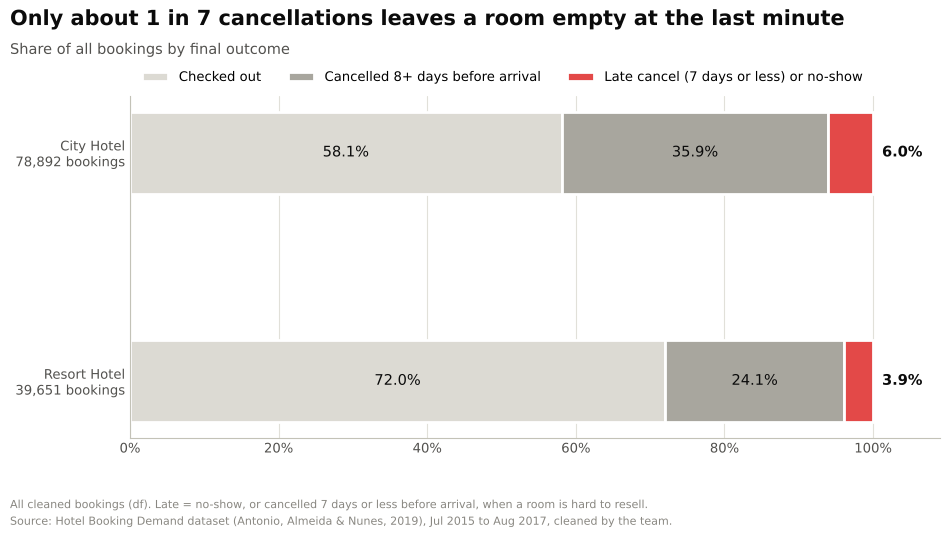

In [10]:
outcome = pd.DataFrame({h: {
    'Checked out': (g['is_canceled'] == 0).mean(),
    'Cancelled 8+ days before arrival': ((g['is_canceled'] == 1) & (g['late_cancel'] == 0)).mean(),
    'Late cancel (7 days or less) or no-show': g['late_cancel'].mean()} for h, g in df.groupby('hotel')}).T.loc[HOTELS]
R['outcome'] = outcome.round(4).to_dict()
late_share_of_canc = (df['late_cancel'].sum() / df['is_canceled'].sum())
R['late_share_of_cancellations'] = round(late_share_of_canc, 3)

fig, ax = chart(f'Only about 1 in {round(1 / late_share_of_canc)} cancellations leaves a room empty at the last minute',
                'Share of all bookings by final outcome')
y = np.array([1, 0])
left = np.zeros(2)
for col, c in zip(outcome.columns, [KEPT, CONTEXT, LOSS]):
    vals = outcome[col].values
    ax.barh(y, vals, left=left, color=c, height=0.36, edgecolor='white', linewidth=2, label=col)
    for yi, v, l in zip(y, vals, left):
        if v > 0.1:
            ax.text(l + v / 2, yi, f'{v:.1%}', ha='center', va='center', color=INK, fontsize=10.5)
        else:
            ax.text(l + v + 0.012, yi, f'{v:.1%}', ha='left', va='center', color=INK, fontsize=10.5, fontweight='bold')
    left += vals
counts = df['hotel'].value_counts()
ax.set_yticks(y, [f'{h}\n{counts[h]:,} bookings' for h in HOTELS])
ax.set_xlim(0, 1.09)
ax.xaxis.set_major_formatter(PCT)
ax.set_xticks([0, .2, .4, .6, .8, 1])
hbar_grid(ax)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=3)
save(fig, '01_outcome_by_hotel', 'All cleaned bookings (df). Late = no-show, or cancelled 7 days or less before arrival, when a room is hard to resell.', left=0.16)

{'resort': np.float64(28.0), 'mix': np.float64(3.6), 'within': np.float64(2.1), 'non_refund': np.float64(8.2), 'city': np.float64(41.9)}


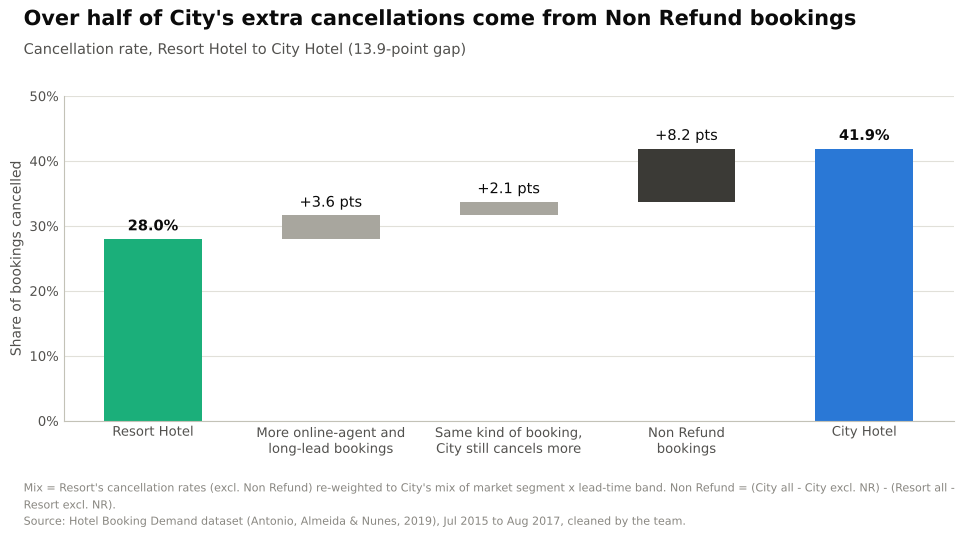

In [11]:
# Why does City cancel more? Accounting split of the 13.9-point gap.
res, cty = df[df.hotel == 'Resort Hotel'], df[df.hotel == 'City Hotel']
res_x, cty_x = res[res.deposit_type != 'Non Refund'], cty[cty.deposit_type != 'Non Refund']
key = ['market_segment', 'lead_time_band']
r_rates = res_x.groupby(key, observed=True)['is_canceled'].mean()
c_mix = cty_x.groupby(key, observed=True).size() / len(cty_x)
j = pd.concat([r_rates.rename('rate'), c_mix.rename('w')], axis=1).dropna()
resort_on_city_mix = (j['rate'] * j['w']).sum() / j['w'].sum()
r_all, r_x, c_all, c_x = res.is_canceled.mean(), res_x.is_canceled.mean(), cty.is_canceled.mean(), cty_x.is_canceled.mean()
mix, within = resort_on_city_mix - r_x, c_x - resort_on_city_mix
nonref = (c_all - c_x) - (r_all - r_x)
R['waterfall_pts'] = {'resort': r_all * 100, 'mix': mix * 100, 'within': within * 100, 'non_refund': nonref * 100, 'city': c_all * 100}
print({k: round(v, 1) for k, v in R['waterfall_pts'].items()})

steps = [('Resort Hotel', r_all, RESORT, True), ('More online-agent and\nlong-lead bookings', mix, CONTEXT, False),
         ('Same kind of booking,\nCity still cancels more', within, CONTEXT, False),
         ('Non Refund\nbookings', nonref, FOCUS, False), ('City Hotel', c_all, CITY, True)]
fig, ax = chart('Over half of City\'s extra cancellations come from Non Refund bookings',
                f'Cancellation rate, Resort Hotel to City Hotel ({(c_all - r_all) * 100:.1f}-point gap)')
base = 0
for i, (lab, v, c, total) in enumerate(steps):
    bottom = 0 if total else base
    ax.bar(i, v, bottom=bottom, color=c, width=0.55)
    top = bottom + v
    ax.text(i, top + 0.008, f'{v:.1%}' if total else f'+{v * 100:.1f} pts', ha='center', va='bottom', color=INK,
            fontsize=10.5, fontweight='bold' if total else 'normal')
    base = v if total else base + v
ax.set_xticks(range(len(steps)), [s[0] for s in steps])
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(PCT)
ax.set_ylabel('Share of bookings cancelled')
save(fig, '02_city_resort_gap', 'Mix = Resort\'s cancellation rates (excl. Non Refund) re-weighted to City\'s mix of market segment x lead-time band. '
     'Non Refund = (City all - City excl. NR) - (Resort all - Resort excl. NR).')

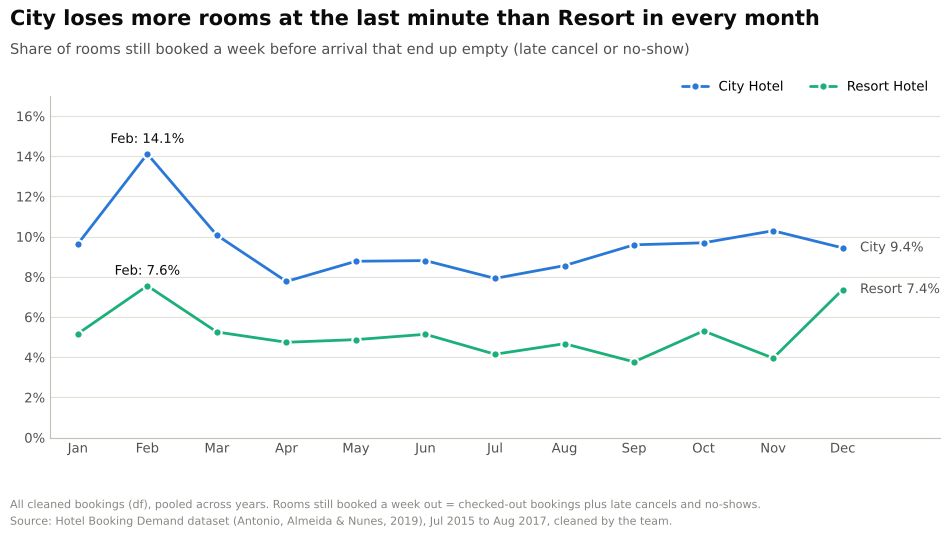

In [12]:
# Seasonality of rooms that end up empty (feeds the overbooking section)
act = df.assign(active=((df.is_canceled == 0) | (df.late_cancel == 1)).astype(int))
monthly = act.groupby(['hotel', 'arrival_date_month'], observed=True).apply(
    lambda g: g['late_cancel'].sum() / g['active'].sum()).unstack(0)
R['monthly_empty_share'] = monthly.round(4).to_dict()
fig, ax = chart('City loses more rooms at the last minute than Resort in every month',
                'Share of rooms still booked a week before arrival that end up empty (late cancel or no-show)')
x = np.arange(12)
for h in HOTELS:
    v = monthly[h].values
    ax.plot(x, v, color=HOTEL_COLOR[h], marker='o', markersize=6, markeredgecolor='white', markeredgewidth=1.5, label=h)
    ax.text(11.25, v[-1], f'{h.split()[0]} {v[-1]:.1%}', va='center', color=INK2, fontsize=9.5)
    imax = int(np.argmax(v))
    ax.annotate(f'{MONTHS[imax][:3]}: {v[imax]:.1%}', (imax, v[imax]), xytext=(0, 8), textcoords='offset points',
                ha='center', color=INK, fontsize=9.5)
ax.set_xticks(x, [m[:3] for m in MONTHS])
ax.set_xlim(-0.4, 12.4)
ax.set_ylim(0, 0.17)
ax.yaxis.set_major_formatter(PCT)
ax.legend(loc='upper right', ncol=2, bbox_to_anchor=(1, 1.08))
save(fig, '03_monthly_empty_rooms', 'All cleaned bookings (df), pooled across years. Rooms still booked a week out = checked-out bookings plus late cancels and no-shows.')

## 4. Part 2: how much money is at stake?

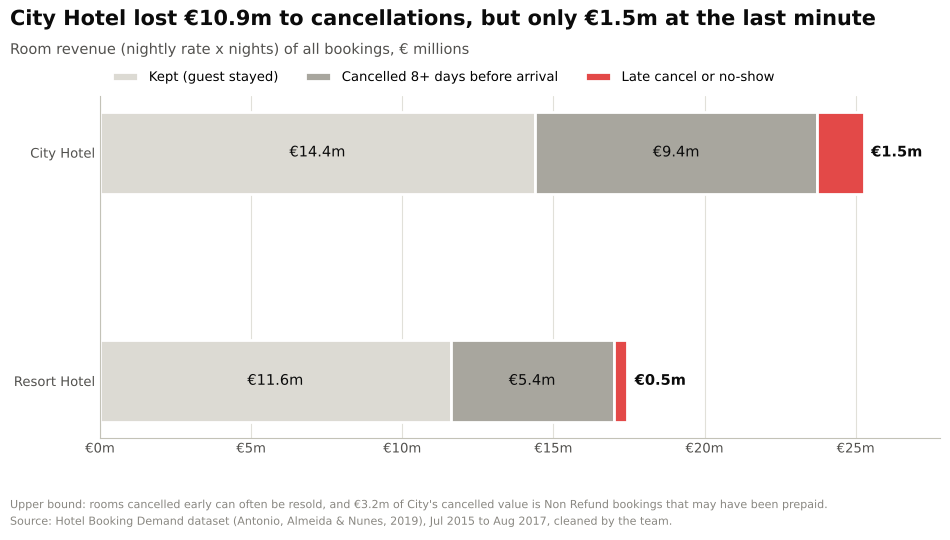

In [13]:
money = pd.DataFrame({h: {
    'Kept (guest stayed)': g.loc[g.is_canceled == 0, 'booking_value'].sum() / 1e6,
    'Cancelled 8+ days before arrival': g.loc[(g.is_canceled == 1) & (g.late_cancel == 0), 'booking_value'].sum() / 1e6,
    'Late cancel or no-show': g.loc[g.late_cancel == 1, 'booking_value'].sum() / 1e6,
    'Non Refund cancelled': g.loc[(g.is_canceled == 1) & (g.deposit_type == 'Non Refund'), 'booking_value'].sum() / 1e6}
    for h, g in df.groupby('hotel')}).T.loc[HOTELS]
R['money_m'] = money.round(3).to_dict()
c_lost = money.loc['City Hotel', ['Cancelled 8+ days before arrival', 'Late cancel or no-show']].sum()
c_late = money.loc['City Hotel', 'Late cancel or no-show']

fig, ax = chart(f'City Hotel lost €{c_lost:.1f}m to cancellations, but only €{c_late:.1f}m at the last minute',
                'Room revenue (nightly rate x nights) of all bookings, € millions')
left = np.zeros(2)
cols = ['Kept (guest stayed)', 'Cancelled 8+ days before arrival', 'Late cancel or no-show']
for col, c in zip(cols, [KEPT, CONTEXT, LOSS]):
    vals = money.loc[HOTELS, col].values
    ax.barh(y, vals, left=left, color=c, height=0.36, edgecolor='white', linewidth=2, label=col)
    for yi, v, l in zip(y, vals, left):
        if v > 2:
            ax.text(l + v / 2, yi, f'€{v:.1f}m', ha='center', va='center', color=INK, fontsize=10.5)
        else:
            ax.text(l + v + 0.25, yi, f'€{v:.1f}m', ha='left', va='center', color=INK, fontsize=10.5, fontweight='bold')
    left += vals
ax.set_yticks(y, HOTELS)
ax.set_xlim(0, left.max() * 1.1)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f'€{v:.0f}m'))
hbar_grid(ax)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=3)
save(fig, '04_money_by_hotel', f'Upper bound: rooms cancelled early can often be resold, and €{money.loc["City Hotel", "Non Refund cancelled"]:.1f}m of City\'s cancelled value is Non Refund bookings that may have been prepaid.',
     left=0.13)

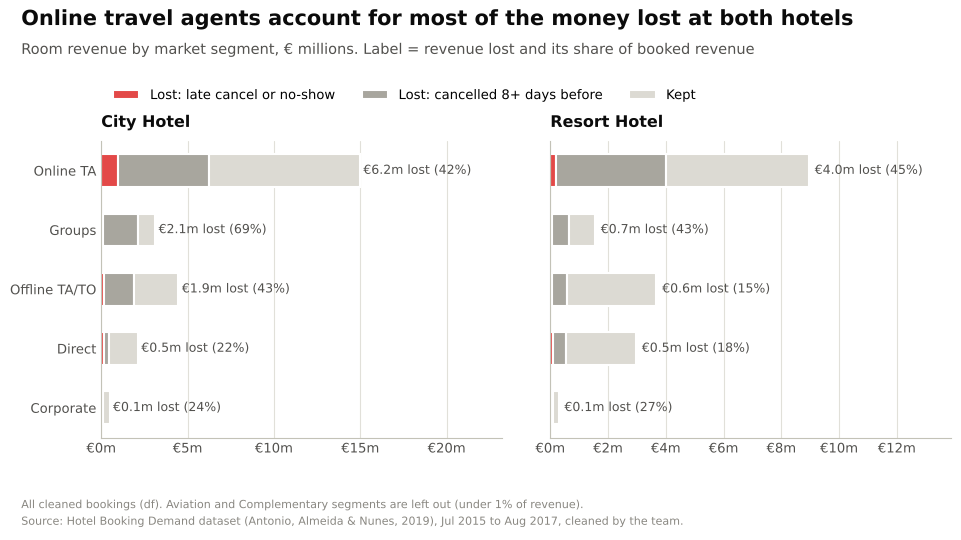

In [14]:
seg_money = []
for h, g in df.groupby('hotel'):
    for s in SEGMENTS:
        gs = g[g.market_segment == s]
        seg_money.append({'hotel': h, 'segment': s,
                          'late': gs.loc[gs.late_cancel == 1, 'booking_value'].sum() / 1e6,
                          'early': gs.loc[(gs.is_canceled == 1) & (gs.late_cancel == 0), 'booking_value'].sum() / 1e6,
                          'kept': gs.loc[gs.is_canceled == 0, 'booking_value'].sum() / 1e6})
seg_money = pd.DataFrame(seg_money)
seg_money['lost'] = seg_money.late + seg_money.early
seg_money['lost_share_of_booked'] = seg_money.lost / (seg_money.lost + seg_money.kept)
seg_money['share_of_hotel_loss'] = seg_money.lost / seg_money.groupby('hotel').lost.transform('sum')
R['segment_money'] = seg_money.round(4).to_dict(orient='records')

fig, axes = chart('Online travel agents account for most of the money lost at both hotels',
                  'Room revenue by market segment, € millions. Label = revenue lost and its share of booked revenue', ncols=2, sharey=True)
yy = np.arange(len(SEGMENTS))[::-1]
for ax, h in zip(axes, HOTELS):
    g = seg_money[seg_money.hotel == h].set_index('segment').loc[SEGMENTS]
    l = np.zeros(len(SEGMENTS))
    for col, c, lab in [('late', LOSS, 'Lost: late cancel or no-show'), ('early', CONTEXT, 'Lost: cancelled 8+ days before'), ('kept', KEPT, 'Kept')]:
        ax.barh(yy, g[col].values, left=l, color=c, height=0.55, edgecolor='white', linewidth=1.5, label=lab)
        l += g[col].values
    for yi, (s, r) in zip(yy, g.iterrows()):
        ax.text(r.late + r.early + r.kept + 0.2, yi, f'€{r.lost:.1f}m lost ({r.lost_share_of_booked:.0%})', va='center', fontsize=9, color=INK2)
    ax.set_title(h)
    ax.set_xlim(0, l.max() * 1.55)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f'€{v:.0f}m'))
    hbar_grid(ax)
axes[0].set_yticks(yy, SEGMENTS)
axes[0].legend(loc='lower left', bbox_to_anchor=(0, 1.09), ncol=3)
save(fig, '05_money_by_channel', 'All cleaned bookings (df). Aviation and Complementary segments are left out (under 1% of revenue).', top=0.72, left=0.12, wspace=0.12)

## 5. Part 3: booking window (lead time)

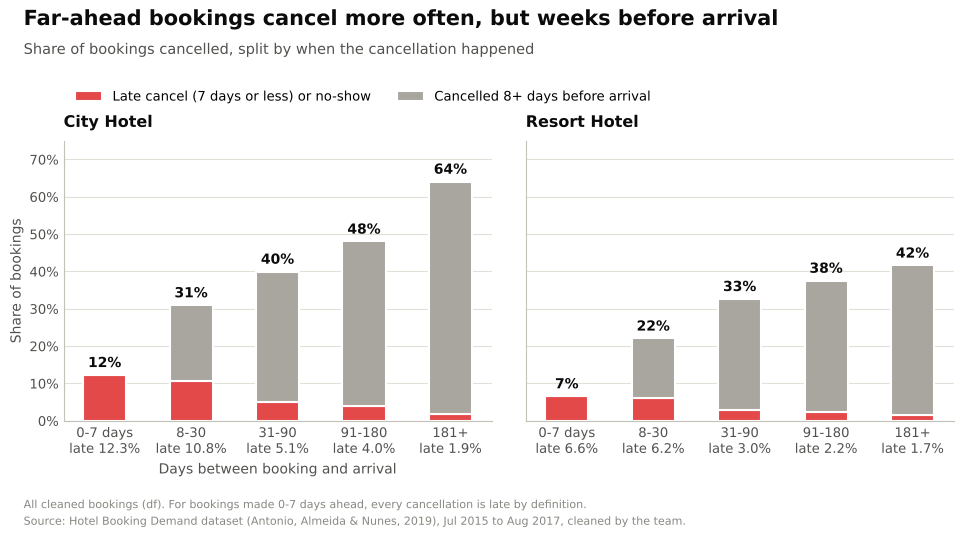

In [15]:
lead = df.groupby(['hotel', 'lead_time_band'], observed=True).agg(
    n=('is_canceled', 'size'), cancel=('is_canceled', 'mean'), late=('late_cancel', 'mean')).reset_index()
lead['early'] = lead.cancel - lead.late
R['lead'] = lead.round(4).to_dict(orient='records')

fig, axes = chart('Far-ahead bookings cancel more often, but weeks before arrival',
                  'Share of bookings cancelled, split by when the cancellation happened', ncols=2, sharey=True)
xb = np.arange(len(BANDS))
for ax, h in zip(axes, HOTELS):
    g = lead[lead.hotel == h].set_index('lead_time_band').loc[BANDS]
    ax.bar(xb, g.late, color=LOSS, width=0.5, edgecolor='white', linewidth=1.5, label='Late cancel (7 days or less) or no-show')
    ax.bar(xb, g.early, bottom=g.late, color=CONTEXT, width=0.5, edgecolor='white', linewidth=1.5, label='Cancelled 8+ days before arrival')
    for xi, (b, r) in zip(xb, g.iterrows()):
        ax.text(xi, r.cancel + 0.012, f'{r.cancel:.0%}', ha='center', va='bottom', fontsize=10, fontweight='bold', color=INK)
    ax.set_xticks(xb, [f'{lab}\nlate {v:.1%}' for lab, v in zip(BAND_LABELS, g.late)])
    ax.set_title(h)
    ax.set_ylim(0, 0.75)
    ax.yaxis.set_major_formatter(PCT)
axes[0].set_ylabel('Share of bookings')
axes[0].legend(loc='lower left', bbox_to_anchor=(0, 1.09), ncol=2)
axes[0].set_xlabel('Days between booking and arrival')
save(fig, '06_lead_time_early_late', 'All cleaned bookings (df). For bookings made 0-7 days ahead, every cancellation is late by definition.', top=0.72, bottom=0.22, wspace=0.08)

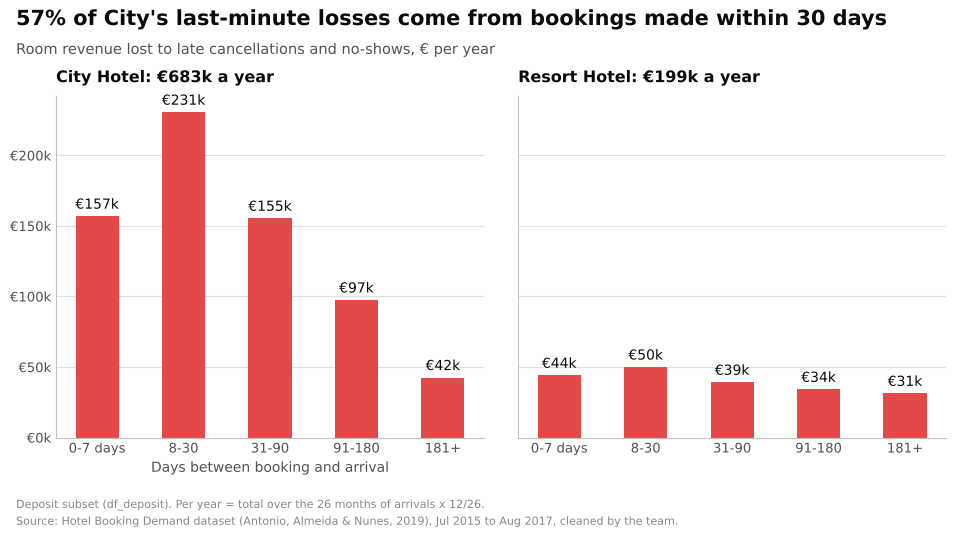

In [16]:
late_eur = df_deposit[df_deposit.late_cancel == 1].groupby(['hotel', 'lead_time_band'], observed=True)['booking_value'].sum() / YEARS
R['late_eur_per_year_by_lead'] = late_eur.round(0).unstack().to_dict()
share_short = {h: late_eur[h].loc[['0-7', '8-30']].sum() / late_eur[h].sum() for h in HOTELS}
R['late_eur_share_lead_le30'] = {h: round(v, 3) for h, v in share_short.items()}

fig, axes = chart(f'{share_short["City Hotel"]:.0%} of City\'s last-minute losses come from bookings made within 30 days',
                  'Room revenue lost to late cancellations and no-shows, € per year', ncols=2, sharey=True)
for ax, h in zip(axes, HOTELS):
    v = late_eur[h].loc[BANDS]
    ax.bar(xb, v.values, color=LOSS, width=0.5)
    for xi, val in zip(xb, v.values):
        ax.text(xi, val + 3000, f'€{val / 1000:.0f}k', ha='center', va='bottom', fontsize=10, color=INK)
    ax.set_xticks(xb, BAND_LABELS)
    ax.set_title(f'{h}: €{v.sum() / 1000:.0f}k a year')
    ax.yaxis.set_major_formatter(FuncFormatter(lambda val, p: f'€{val / 1000:.0f}k'))
axes[0].set_xlabel('Days between booking and arrival')
save(fig, '07_late_loss_by_lead', 'Deposit subset (df_deposit). Per year = total over the 26 months of arrivals x 12/26.', wspace=0.08)

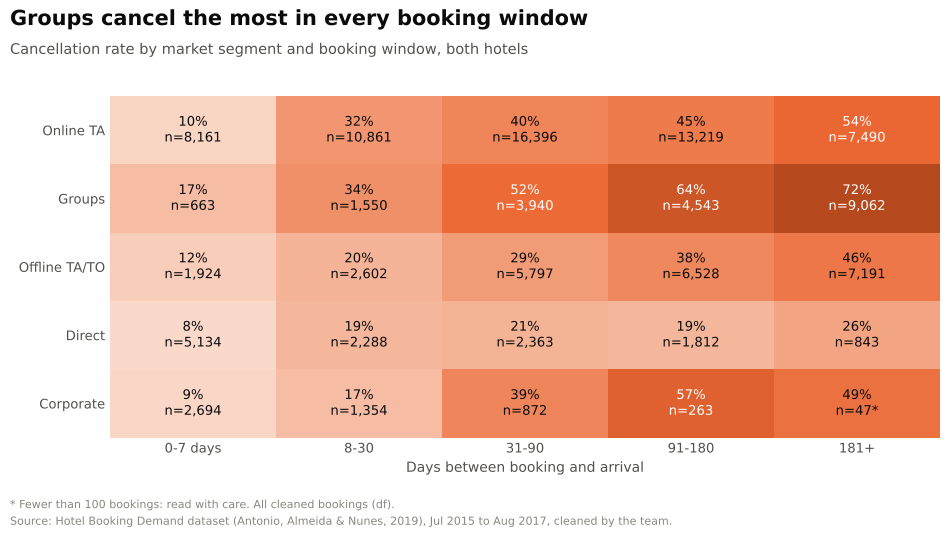

In [17]:
heat = df[df.market_segment.isin(SEGMENTS)].groupby(['market_segment', 'lead_time_band'], observed=True)['is_canceled'].agg(['mean', 'size'])
rate = heat['mean'].unstack().loc[SEGMENTS, BANDS]
size = heat['size'].unstack().loc[SEGMENTS, BANDS]
cmap = LinearSegmentedColormap.from_list('cancel', ['#fdf1ea', '#f3a27f', '#eb6834', '#9c3a12'])
fig, ax = chart('Groups cancel the most in every booking window',
                'Cancellation rate by market segment and booking window, both hotels')
ax.imshow(rate.values, cmap=cmap, vmin=0, vmax=0.8, aspect='auto')
for i in range(rate.shape[0]):
    for k in range(rate.shape[1]):
        v, n = rate.values[i, k], size.values[i, k]
        ax.text(k, i, f'{v:.0%}\nn={n:,}{"*" if n < 100 else ""}', ha='center', va='center', fontsize=9.5,
                color='white' if v > 0.5 else INK)
ax.set_xticks(range(len(BANDS)), BAND_LABELS)
ax.set_yticks(range(len(SEGMENTS)), SEGMENTS)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xlabel('Days between booking and arrival')
save(fig, '08_segment_lead_heatmap', '* Fewer than 100 bookings: read with care. All cleaned bookings (df).', left=0.14)

## 6. Part 4: channel

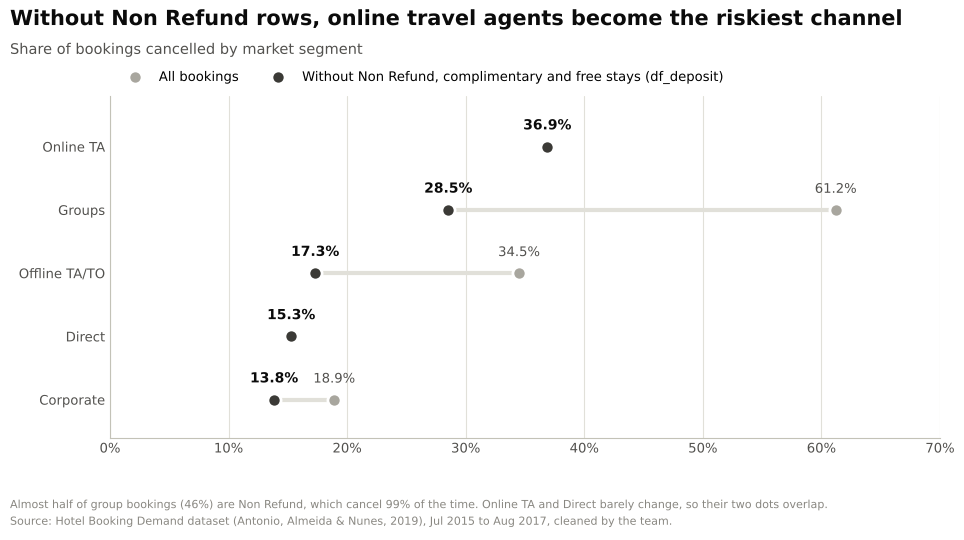

In [18]:
ch = pd.DataFrame({'All bookings': df.groupby('market_segment').is_canceled.mean(),
                   'Without Non Refund (deposit subset)': df_deposit.groupby('market_segment').is_canceled.mean()}).loc[SEGMENTS]
ch = ch.sort_values('Without Non Refund (deposit subset)')
R['channel'] = ch.round(4).to_dict()
fig, ax = chart('Without Non Refund rows, online travel agents become the riskiest channel',
                'Share of bookings cancelled by market segment')
yc = np.arange(len(ch))
for yi, (s, r) in zip(yc, ch.iterrows()):
    a, b = r['All bookings'], r['Without Non Refund (deposit subset)']
    ax.plot([a, b], [yi, yi], color=GRID, linewidth=3, zorder=1)
    ax.text(b, yi + 0.22, f'{b:.1%}', ha='center', va='bottom', fontsize=10, color=INK, fontweight='bold')
    if abs(a - b) > 0.015:
        ax.text(a, yi + 0.22, f'{a:.1%}', ha='center', va='bottom', fontsize=9.5, color=INK2)
ax.scatter(ch['All bookings'], yc, s=90, color=CONTEXT, edgecolor='white', linewidth=2, zorder=2, label='All bookings')
ax.scatter(ch['Without Non Refund (deposit subset)'], yc, s=90, color=FOCUS, edgecolor='white', linewidth=2, zorder=3,
           label='Without Non Refund, complimentary and free stays (df_deposit)')
ax.set_yticks(yc, ch.index)
ax.set_ylim(-0.6, len(ch) - 0.2)
ax.set_xlim(0, 0.7)
ax.xaxis.set_major_formatter(PCT)
hbar_grid(ax)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2)
save(fig, '09_channel_dumbbell', f'Almost half of group bookings ({(df[df.market_segment == "Groups"].deposit_type == "Non Refund").mean():.0%}) are Non Refund, which cancel 99% of the time. '
     'Online TA and Direct barely change, so their two dots overlap.', left=0.14)

## 7. Part 5: booking history

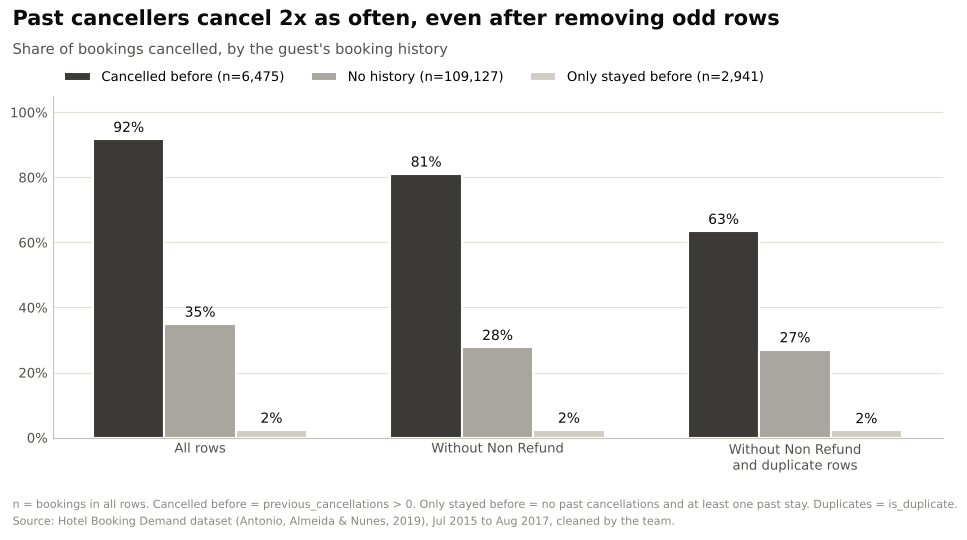

In [19]:
versions = {'All rows': np.ones(len(df), bool),
            'Without Non Refund': (df.deposit_type != 'Non Refund').values,
            'Without Non Refund\nand duplicate rows': clean_rows.values}
groups = [('has', 'Cancelled before', FOCUS), ('none', 'No history', CONTEXT), ('stayed', 'Only stayed before', '#cfcdc5')]
hist_rates = {v: {g: df.loc[m & (hist_all == g), 'is_canceled'].mean() for g, _, _ in groups} for v, m in versions.items()}
hist_n = {g: int((hist_all == g).sum()) for g, _, _ in groups}
R['history'] = {'rates': {k.replace('\n', ' '): {g: round(v, 4) for g, v in d.items()} for k, d in hist_rates.items()}, 'n_all': hist_n,
                'repeat_and_prior_cancel_n': int(((hist_all == 'has') & (df.is_repeated_guest == 1)).sum())}
fig, ax = chart('Past cancellers cancel 2x as often, even after removing odd rows',
                'Share of bookings cancelled, by the guest\'s booking history')
xv = np.arange(len(versions))
w = 0.24
for i, (g, lab, c) in enumerate(groups):
    vals = [hist_rates[v][g] for v in versions]
    ax.bar(xv + (i - 1) * w, vals, width=w, color=c, edgecolor='white', linewidth=1.5, label=f'{lab} (n={hist_n[g]:,})')
    for xi, v in zip(xv + (i - 1) * w, vals):
        ax.text(xi, v + 0.012, f'{v:.0%}', ha='center', va='bottom', fontsize=10, color=INK)
ax.set_xticks(xv, list(versions))
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(PCT)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=3)
save(fig, '10_history', 'n = bookings in all rows. Cancelled before = previous_cancellations > 0. Only stayed before = no past cancellations and at least one past stay. Duplicates = is_duplicate.')

## 8. Part 6: commitment signals (special requests, parking)

Odds ratio for 1+ requests: raw 0.53 | adjusted 0.29


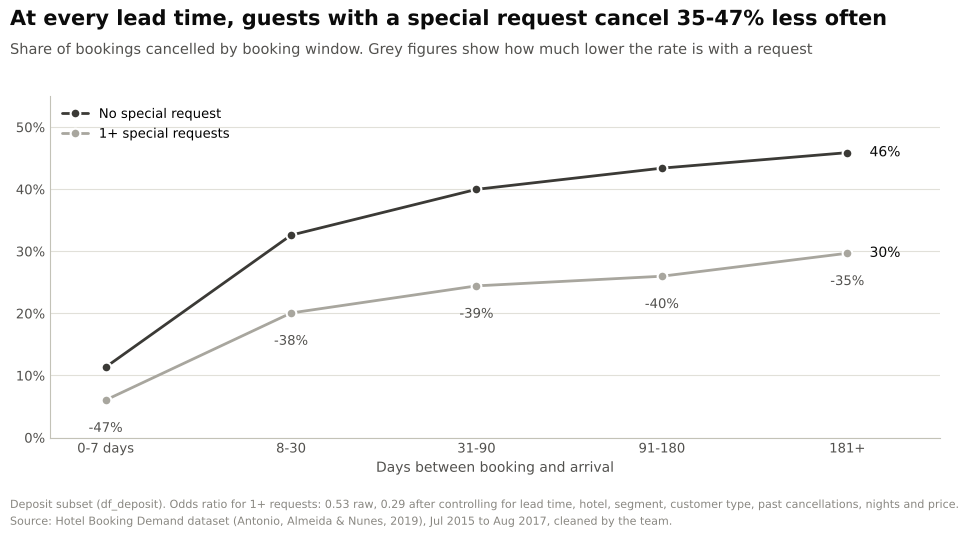

In [20]:
dep = df_deposit.copy()
dep['req'] = (dep.total_of_special_requests > 0).astype(int)
lr = dep.groupby(['lead_time_band', 'req'], observed=True).is_canceled.mean().unstack().loc[BANDS]
R['request_by_lead'] = {('1+ requests' if k else 'No request'): v for k, v in lr.round(4).to_dict().items()}
or_raw = np.exp(smf.logit('is_canceled ~ req', dep).fit(disp=0).params['req'])
or_adj_model = smf.logit('is_canceled ~ req + lead_time + C(hotel) + C(market_segment) + C(customer_type) + previous_cancellations + total_nights + adr',
                         dep).fit(disp=0, maxiter=300)
or_adj = np.exp(or_adj_model.params['req'])
R['request_odds_ratio'] = {'raw': round(or_raw, 3), 'adjusted': round(or_adj, 3),
                           'adjusted_ci': [round(v, 3) for v in np.exp(or_adj_model.conf_int().loc['req'])]}
print('Odds ratio for 1+ requests: raw', round(or_raw, 2), '| adjusted', round(or_adj, 2))

fig, ax = chart('At every lead time, guests with a special request cancel 35-47% less often',
                'Share of bookings cancelled by booking window. Grey figures show how much lower the rate is with a request')
for col, c, lab in [(0, FOCUS, 'No special request'), (1, CONTEXT, '1+ special requests')]:
    ax.plot(xb, lr[col].values, color=c, marker='o', markersize=7, markeredgecolor='white', markeredgewidth=1.5, label=lab)
    ax.text(xb[-1] + 0.12, lr[col].values[-1], f'{lr[col].values[-1]:.0%}', va='center', fontsize=10, color=INK)
for xi, (b, r) in zip(xb, lr.iterrows()):
    ax.text(xi, r[1] - 0.035, f'{r[1] / r[0] - 1:+.0%}', ha='center', va='top', fontsize=9.5, color=INK2)
ax.set_xticks(xb, BAND_LABELS)
ax.set_xlim(-0.3, 4.5)
ax.set_ylim(0, 0.55)
ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel('Days between booking and arrival')
ax.legend(loc='upper left')
save(fig, '11_requests_by_lead', f'Deposit subset (df_deposit). Odds ratio for 1+ requests: {or_raw:.2f} raw, {or_adj:.2f} after controlling for lead time, hotel, '
     'segment, customer type, past cancellations, nights and price.')

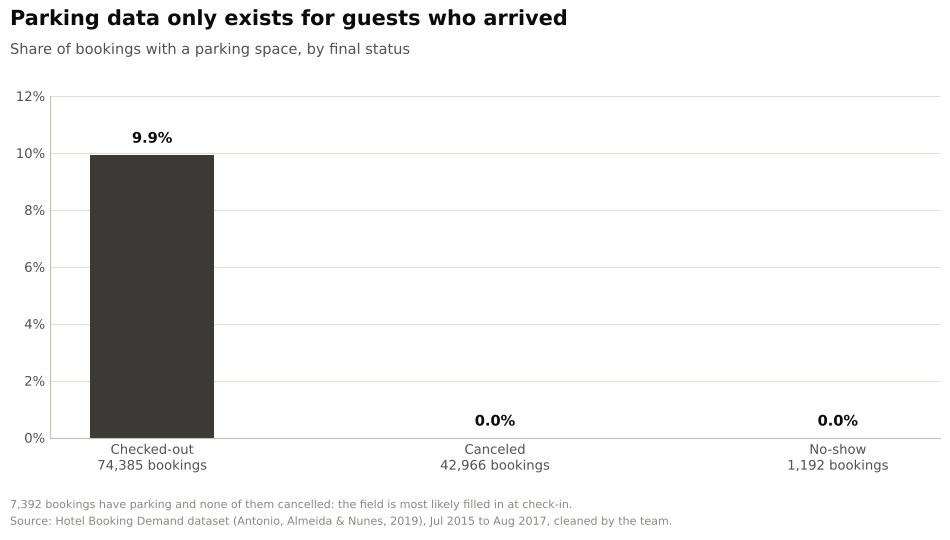

In [21]:
park = df.groupby('cancel_type').required_car_parking_spaces.apply(lambda s: (s > 0).mean()).loc[['Checked-out', 'Canceled', 'No-show']]
park_n = df.cancel_type.value_counts()
R['parking_share_by_status'] = park.round(4).to_dict()
fig, ax = chart('Parking data only exists for guests who arrived',
                'Share of bookings with a parking space, by final status')
ax.bar(range(3), park.values, color=[FOCUS, CONTEXT, CONTEXT], width=0.36)
for i, v in enumerate(park.values):
    ax.text(i, v + 0.003, f'{v:.1%}', ha='center', va='bottom', fontsize=10.5, fontweight='bold', color=INK)
ax.set_xticks(range(3), [f'{s}\n{park_n[s]:,} bookings' for s in park.index])
ax.set_ylim(0, 0.12)
ax.yaxis.set_major_formatter(PCT)
save(fig, '12_parking_leakage', f'{int((df.required_car_parking_spaces > 0).sum()):,} bookings have parking and none of them cancelled: the field is most likely filled in at check-in.')

## 9. Answer, part 1: the deposit

**Policy tested.** A deposit is taken at booking and refunded if the guest cancels more than 7 days before arrival. It is kept if the guest cancels 7 days or less before arrival or does not show up. Those are the cancellations the hotel cannot resell, so this is where a deposit protects revenue.

**What the data can and cannot say.** The data has no deposit amount column, 99.8% of the deposit subset has no deposit at all, and only 162 bookings in the whole file are Refundable. The data therefore cannot show at what amount guests change their behaviour. It can show who causes the losses, how much money each deposit level would recover, and how much demand the hotel could afford to lose before a deposit stops paying. Guest response is handled as scenarios: 0%, 10%, 25% and 50% fewer late cancellations.

The rule’s cut-offs. €540 is where the top value group starts: about 14% of City bookings, but 41% of City's late-cancel losses (Figure 13a). The rule is checked on 2017 arrivals (Figure 13b).

**Special requests.** Guests with at least one special request cancel late less often (Part 6), so Figure 14 splits each bar into guests with and without a request. Both groups stay in the rule, because guests with a request still cause about 40% of City's late-cancel losses.

**Resale assumption.** "Recovered" assumes a late-cancelled room is never resold, and that a guest who switches to cancelling early frees a room that is resold. Both are assumptions; if some late-cancelled rooms are resold, the true loss and the amount recovered are both smaller.

,Share of bookings,Share of late-cancel losses,Loss per booking (€)
Booking value (€),,,
0-130,16.5%,7.3%,10
130-230,21.2%,12.3%,13
230-340,24.2%,17.9%,17
340-540,24.0%,21.8%,21
540+,14.2%,40.8%,65


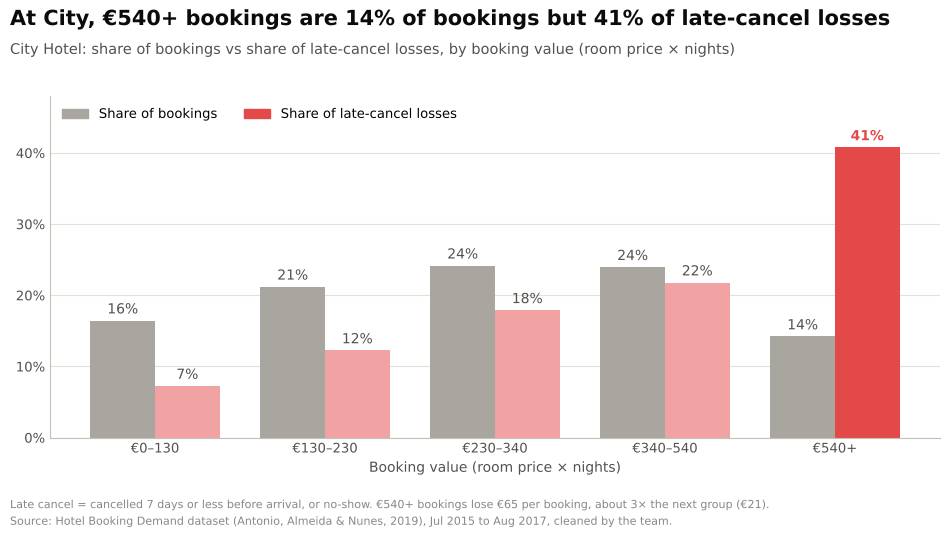

In [22]:
# ---------- Figure 13a. Why €540? City bookings by value group ----------
# Booking value = price per night x number of nights. value_band splits bookings into 5 groups (made in cell 5).
from matplotlib.patches import Patch

dep['late_value'] = dep.late_cancel * dep.booking_value   # money lost to late cancels (same line as in the rule cell)
city_dep = dep[dep.hotel == 'City Hotel']
by_value = city_dep.groupby('value_band', observed=True).agg(
    bookings=('late_cancel', 'size'),
    late_loss=('late_value', 'sum'))
# numbers used by BOTH the table and the chart
by_value['share_book'] = by_value.bookings / by_value.bookings.sum()
by_value['share_loss'] = by_value.late_loss / by_value.late_loss.sum()
by_value['loss_per'] = by_value.late_loss / by_value.bookings

value_table = pd.DataFrame({
    'Share of bookings': by_value.share_book.map('{:.1%}'.format),
    'Share of late-cancel losses': by_value.share_loss.map('{:.1%}'.format),
    'Loss per booking (€)': by_value.loss_per.round(0).astype(int)})
value_table.index.name = 'Booking value (€)'
display(value_table)

# ---- Chart 13a: why €540? Same numbers as the table above
LABELS = ['€0–130', '€130–230', '€230–340', '€340–540', '€540+']
x, w = np.arange(len(by_value)), 0.38
top = by_value.iloc[-1]          # the €540+ group
nxt = by_value.iloc[-2]          # the €340–540 group

fig, ax = chart(f'At City, €540+ bookings are {top.share_book:.0%} of bookings but {top.share_loss:.0%} of late-cancel losses',
                'City Hotel: share of bookings vs share of late-cancel losses, by booking value (room price × nights)')
ax.bar(x - w/2, by_value.share_book, w, color=CONTEXT)
ax.bar(x + w/2, by_value.share_loss, w, color=[LOSS if i == len(x) - 1 else '#f0a3a2' for i in x])
for i in x:
    last = i == len(x) - 1
    ax.text(x[i] - w/2, by_value.share_book.iloc[i] + 0.01, f'{by_value.share_book.iloc[i]:.0%}', ha='center', color=INK2, fontsize=10)
    ax.text(x[i] + w/2, by_value.share_loss.iloc[i] + 0.01, f'{by_value.share_loss.iloc[i]:.0%}', ha='center',
            color=LOSS if last else INK2, fontsize=10, fontweight='bold' if last else 'normal')
ax.set_xticks(x, LABELS)
ax.yaxis.set_major_formatter(PCT)
ax.set_ylim(0, 0.48)
ax.set_xlabel('Booking value (room price × nights)')
ax.legend(handles=[Patch(color=CONTEXT, label='Share of bookings'), Patch(color=LOSS, label='Share of late-cancel losses')],
          loc='upper left', ncol=2)
save(fig, '13a_why_540', f'Late cancel = cancelled 7 days or less before arrival, or no-show. €540+ bookings lose €{top.loss_per:.0f} per booking, '
                       f'about {top.loss_per / nxt.loss_per:.0f}× the next group (€{nxt.loss_per:.0f}).')

Late-cancel model, out-of-time AUC (2017): 0.671
All years
  Booked 30 days or less ahead: 33.50%
  Booking worth €540+:          14.49%
  Cancelled before:             3.14%
  At least one of the three:    46.37%
  Asked (loyal guests removed): 45.10%
2017 only
  Booked 30 days or less ahead: 28.93%
  Booking worth €540+:          19.61%
  Cancelled before:             0.69%
  At least one of the three:    45.00%
  Asked (loyal guests removed): 43.71%


,Asked (2017) [chart],Share of late-cancel losses from them (2017) [chart],Points above random (2017) [chart],Asked (all years),Share of late-cancel losses from them (all years),Late-cancel rate: asked (all years),Late-cancel rate: not asked (all years),"Model, same share asked (2017)"
City Hotel,43.71%,75.78%,32.08,45.10%,72.58%,9.24%,4.83%,73.11%
Resort Hotel,33.36%,50.36%,16.99,36.55%,51.12%,6.61%,2.17%,64.33%


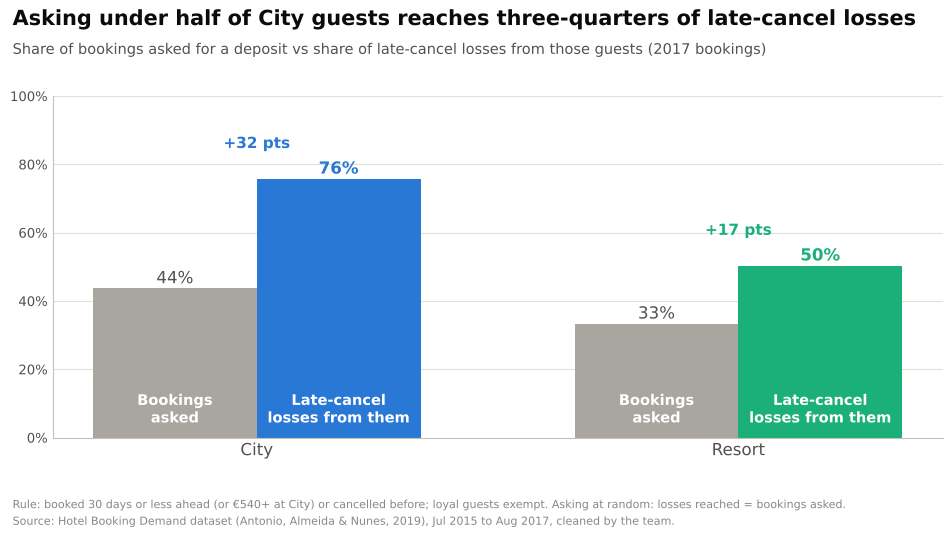

In [23]:
dep['prior_cancel'] = (dep.previous_cancellations > 0).astype(int)
dep['prior_stay'] = (dep.previous_bookings_not_canceled > 0).astype(int)
dep['kids'] = ((dep.children + dep.babies) > 0).astype(int)
dep['month'] = dep.arrival_date_month.astype(str)
dep['late_value'] = dep.late_cancel * dep.booking_value

# Booking-time model of late cancellation: trained on 2015-16 arrivals, tested on 2017 arrivals
# (robustness check for the report only; not shown on the chart)
formula = ('late_cancel ~ C(hotel) + C(lead_time_band) + C(market_segment) + C(customer_type) + req + prior_cancel + prior_stay'
           ' + is_repeated_guest + total_nights + adr + kids + C(month) + has_agent + days_in_waiting_list')
train, test = dep[dep.arrival_date < '2017-01-01'].copy(), dep[dep.arrival_date >= '2017-01-01'].copy()
late_model = smf.logit(formula, train).fit(disp=0, maxiter=300)
test['p_late'] = late_model.predict(test)
test['exp_loss'] = test.p_late * test.booking_value
auc = roc_auc_score(test.late_cancel, test.p_late)
R['late_model'] = {'auc_test_2017': round(auc, 3), 'n_train': len(train), 'n_test': len(test),
                   'odds_ratios': np.exp(late_model.params).round(3).to_dict()}
print(f'Late-cancel model, out-of-time AUC (2017): {auc:.3f}')


def deposit_rule(frame):
    """Who is asked for a deposit. Booking-time information only."""
    city = frame.hotel == 'City Hotel'
    short = frame.lead_time <= 30
    big = frame.booking_value >= 540
    prior_cancel = frame.previous_cancellations > 0
    loyal = (frame.previous_bookings_not_canceled > 0) & ~prior_cancel
    return ((short | (city & big)) & ~loyal) | prior_cancel


dep['target'] = deposit_rule(dep)
test['target'] = deposit_rule(test)

# How many City bookings meet each condition (all years vs 2017)
for name, data in [('All years', dep), ('2017 only', test)]:
    city = data[data.hotel == 'City Hotel']
    short = city.lead_time <= 30
    big = city.booking_value >= 540
    cancelled_before = city.previous_cancellations > 0
    print(name)
    print('  Booked 30 days or less ahead:', f'{short.mean():.2%}')
    print('  Booking worth €540+:         ', f'{big.mean():.2%}')
    print('  Cancelled before:            ', f'{cancelled_before.mean():.2%}')
    print('  At least one of the three:   ', f'{(short | big | cancelled_before).mean():.2%}')
    print('  Asked (loyal guests removed):', f'{city.target.mean():.2%}')

# ---------- ONE table for the rule. The chart below is drawn from its first three columns ----------
rule_stats = {}   # same keys as before, so later cells (summary table) keep working
for h in HOTELS:
    g, gt = dep[dep.hotel == h], test[test.hotel == h]
    gs = gt.sort_values('exp_loss', ascending=False)
    k = int(round(gt.target.mean() * len(gs)))
    rule_stats[h] = {
        'test_share_asked': gt.target.mean(),                                                        # 2017 = the chart
        'test_share_late_eur_covered': gt.loc[gt.target, 'late_value'].sum() / gt.late_value.sum(),  # 2017 = the chart
        'share_asked': g.target.mean(),                                                              # all years = the NOTE
        'share_late_eur_covered': g.loc[g.target, 'late_value'].sum() / g.late_value.sum(),          # all years = the NOTE
        'p_late_target': g.loc[g.target, 'late_cancel'].mean(),
        'p_late_rest': g.loc[~g.target, 'late_cancel'].mean(),
        'model_covered_at_same_share': gs.late_value.iloc[:k].sum() / gs.late_value.sum()}          # report only
rule_table = pd.DataFrame(rule_stats).T.rename(columns={
    'test_share_asked': 'Asked (2017) [chart]',
    'test_share_late_eur_covered': 'Share of late-cancel losses from them (2017) [chart]',
    'share_asked': 'Asked (all years)',
    'share_late_eur_covered': 'Share of late-cancel losses from them (all years)',
    'p_late_target': 'Late-cancel rate: asked (all years)',
    'p_late_rest': 'Late-cancel rate: not asked (all years)',
    'model_covered_at_same_share': 'Model, same share asked (2017)'})
rule_table.insert(2, 'Points above random (2017) [chart]',
                  (rule_table['Share of late-cancel losses from them (2017) [chart]'] - rule_table['Asked (2017) [chart]']) * 100)
R['deposit_rule'] = {h: {k: round(v, 4) for k, v in d.items()} for h, d in rule_stats.items()}

# shown without rounding; only the chart rounds
display(rule_table.style.format({c: '{:.2%}' for c in rule_table.columns if 'Points' not in c} |
                                {'Points above random (2017) [chart]': '{:.2f}'}))

# ---- Chart 13b: does the rule work? Drawn straight from rule_table (2017 columns)
fig, ax = chart('Asking under half of City guests reaches three-quarters of late-cancel losses',
                'Share of bookings asked for a deposit vs share of late-cancel losses from those guests (2017 bookings)')
xx, w = np.arange(len(HOTELS)), 0.34
for i, h in enumerate(HOTELS):
    a = rule_table.loc[h, 'Asked (2017) [chart]']
    c = rule_table.loc[h, 'Share of late-cancel losses from them (2017) [chart]']
    pts = rule_table.loc[h, 'Points above random (2017) [chart]']
    ax.bar(xx[i] - w/2, a, w, color=CONTEXT)
    ax.bar(xx[i] + w/2, c, w, color=HOTEL_COLOR[h])
    ax.text(xx[i] - w/2, a + 0.015, f'{a:.0%}', ha='center', fontsize=12, color=INK2)
    ax.text(xx[i] + w/2, c + 0.015, f'{c:.0%}', ha='center', fontsize=12, fontweight='bold', color=HOTEL_COLOR[h])
    ax.text(xx[i], max(a, c) + 0.09, f'+{pts:.0f} pts', ha='center', fontsize=11, fontweight='bold', color=HOTEL_COLOR[h])
    ax.text(xx[i] - w/2, 0.03, 'Bookings\nasked', ha='center', va='bottom', color='white', fontsize=10.5, fontweight='bold')
    ax.text(xx[i] + w/2, 0.03, 'Late-cancel\nlosses from them', ha='center', va='bottom', color='white', fontsize=10.5, fontweight='bold')
ax.set_xticks(xx, [h.split()[0] for h in HOTELS], fontsize=12)
ax.yaxis.set_major_formatter(PCT)
ax.set_ylim(0, 1)
save(fig, '13b_deposit_targeting', 'Rule: booked 30 days or less ahead (or €540+ at City) or cancelled before; loyal guests exempt. '
                          'Asking at random: losses reached = bookings asked.')


In [24]:
# ONE table for the deposit size - split by special request, plus the total
REQ_SHARE = 1.0   # 1.0 = everyone pays the full first night (main result). Try 0.8 for a lighter deposit for guests with a request
Q = [0, 0.10, 0.25, 0.50]
Q_LABELS = ['No change in behaviour', '10% fewer late cancels', '25% fewer late cancels', '50% fewer late cancels']
GROUPS = ['No special request', '1+ special request', 'Total']


def deposit_stats(g):
    """Yearly deposit numbers for one group of guests asked for a deposit."""
    T = g.late_value.sum() / YEARS                            # late-cancel revenue at stake, per year
    F = g.loc[g.late_cancel == 1, 'deposit'].sum() / YEARS    # deposits kept from late cancellers, per year
    kept = (g.booking_value * (1 - g.is_canceled)).sum() / YEARS   # revenue from these guests who stay
    out = {'Guests asked per year': len(g) / YEARS, 'Late-cancel rate': g.late_cancel.mean(),
           'Avg first night (€)': g.adr.mean(), 'Avg deposit (€)': g.deposit.mean(),
           'At stake per year (€)': T, 'Kept revenue per year (€)': kept,
           'Deposit kept per guest asked (€)': F / (len(g) / YEARS)}
    for q, ql in zip(Q, Q_LABELS):
        rec = q * T + (1 - q) * F          # q of late cancels avoided (full value saved) + deposits kept from the rest
        out[f'Recovered: {ql}'] = rec
        out[f'Break-even: {ql}'] = rec / kept
    return out


rows = {}
for h in HOTELS:
    g = dep[(dep.hotel == h) & dep.target].copy()
    g['deposit'] = g.adr * np.where(g.total_of_special_requests > 0, REQ_SHARE, 1.0)
    rows[(h, 'No special request')] = deposit_stats(g[g.total_of_special_requests == 0])
    rows[(h, '1+ special request')] = deposit_stats(g[g.total_of_special_requests > 0])
    rows[(h, 'Total')] = deposit_stats(g)
dep_calc = pd.DataFrame(rows).T                  # all numbers, used by the chart
dep_calc.index.names = ['Hotel', 'Guests asked for a deposit']

# check: the two groups add up to the total in every scenario
for h in HOTELS:
    for ql in Q_LABELS:
        c = f'Recovered: {ql}'
        assert abs(dep_calc.loc[(h, 'No special request'), c] + dep_calc.loc[(h, '1+ special request'), c] - dep_calc.loc[(h, 'Total'), c]) < 1

# keep dep_sizing for the later cells (summary table, overbooking), same keys as before
dep_sizing = {}
for h in HOTELS:
    t = dep_calc.loc[(h, 'Total')]
    F = t['Recovered: No change in behaviour']
    dep_sizing[h] = {'target_late_eur_per_year': t['At stake per year (€)'], 'first_night_forfeits_per_year': F,
                     'first_night_as_share_of_late_value': F / t['At stake per year (€)'],
                     'targeted_bookings_per_year': t['Guests asked per year'], 'kept_revenue_targeted_per_year': t['Kept revenue per year (€)'],
                     'avg_first_night_eur': t['Avg first night (€)'], 'avg_deposit_eur': t['Avg deposit (€)'],
                     'expected_forfeit_per_targeted_guest': F / t['Guests asked per year'], 'p_late_target': t['Late-cancel rate'],
                     'scenarios': {ql: {'recovered_eur_per_year': t[f'Recovered: {ql}'],
                                        'share_of_hotel_late_loss': t[f'Recovered: {ql}'] / (dep[dep.hotel == h].late_value.sum() / YEARS),
                                        'break_even_lost_bookings': t[f'Break-even: {ql}']} for ql in Q_LABELS}}
R['deposit_sizing'] = dep_sizing

# How close to arrival do late cancellations happen, and how many are no-shows?
late = dep[dep.late_cancel == 1]
late_cancelled = late[late.reservation_status == 'Canceled']
print('Median days before arrival (late cancellations):', late_cancelled.days_cancelled_before_arrival.median())
print('Share of late losses that are no-shows:', round((late.reservation_status == 'No-Show').mean() * 100, 1), '%')

# The table for the report (same numbers as the chart). Not rounded: only the chart rounds.
# Note: the Total row is a weighted average (each guest counts once), not the mean of the two rows above.
deposit_table = pd.DataFrame({
    'Guests asked per year': dep_calc['Guests asked per year'].map('{:,.1f}'.format),
    'Late-cancel rate': dep_calc['Late-cancel rate'].map('{:.2%}'.format),
    'Avg deposit (€)': dep_calc['Avg deposit (€)'].map('€{:,.2f}'.format),
    'Deposit kept per guest asked (€)': dep_calc['Deposit kept per guest asked (€)'].map('€{:,.2f}'.format),
    **{f'Recovered/yr: {ql}': dep_calc[f'Recovered: {ql}'].map('€{:,.2f}'.format) for ql in Q_LABELS},
    'Pays unless >X% lost (no change)': dep_calc['Break-even: No change in behaviour'].map('{:.2%}'.format)})
deposit_table



Median days before arrival (late cancellations): 3.0
Share of late losses that are no-shows: 19.5 %


Guests asked per year Late-cancel rate Avg deposit (€) Deposit kept per guest asked (€)  \
Hotel        Guests asked for a deposit                                                                                           
City Hotel   No special request                       7,104.9           11.31%         €110.90                           €12.21   
             1+ special request                       6,462.0            6.96%         €128.16                            €8.77   
             Total                                   13,566.9            9.24%         €119.12                           €10.57   
Resort Hotel No special request                       3,534.5            8.00%          €80.97                            €6.69   
             1+ special request                       2,800.6            4.85%         €103.62                            €5.33   
             Total                                    6,335.1            6.61%          €90.98                            €6.09   

                                        Recovered/yr: No change in behaviour Recovered/yr: 10% fewer late cancels Recovered/yr: 25% fewer late cancels  \
Hotel        Guests asked for a deposit                                                                                                                  
City Hotel   No special request                                   €86,777.04                          €106,934.74                          €137,171.28   
             1+ special request                                   €56,660.34                           €71,718.14                           €94,304.84   
             Total                                               €143,437.38                          €178,652.87                          €231,476.11   
Resort Hotel No special request                                   €23,647.25                           €27,211.91                           €32,558.90   
             1+ special request                                   €14,922.50                           €17,653.65                           €21,750.38   
             Total                                                €38,569.75                           €44,865.56                           €54,309.28   

                                        Recovered/yr: 50% fewer late cancels Pays unless >X% lost (no change)  
Hotel        Guests asked for a deposit                                                                        
City Hotel   No special request                                  €187,565.52                            6.37%  
             1+ special request                                  €131,949.33                            2.64%  
             Total                                               €319,514.85                            4.09%  
Resort Hotel No special request                                   €41,470.54                            4.16%  
             1+ special request                                   €28,578.27                            2.09%  
             Total                                                €70,048.81                            3.01%

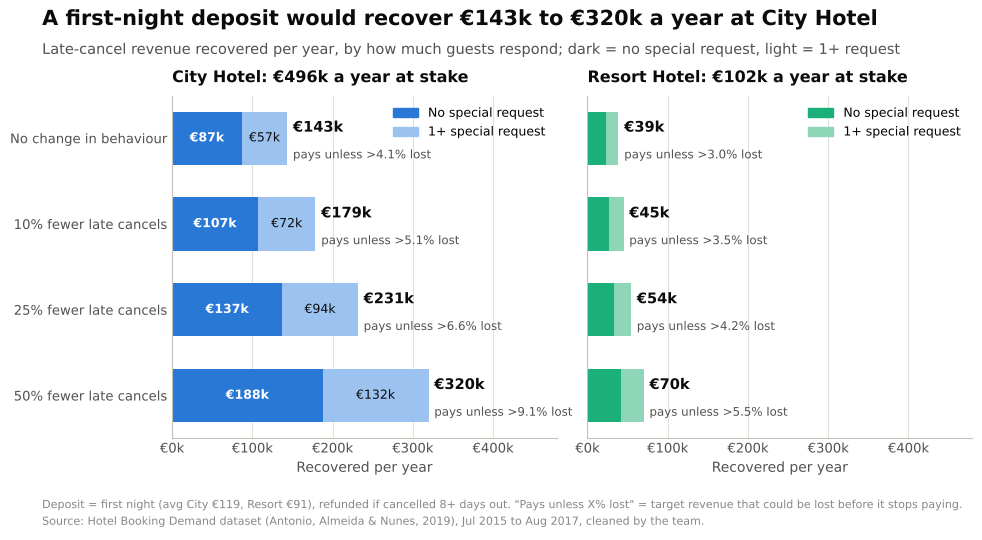

In [25]:
from matplotlib.patches import Patch
LIGHT = {'City Hotel': '#9cc3f0', 'Resort Hotel': '#8fd5b8'}   # lighter tint = 1+ special request

city_total = dep_calc.loc[('City Hotel', 'Total')]
fig, axes = chart(f'A first-night deposit would recover €{city_total["Recovered: " + Q_LABELS[0]] / 1000:.0f}k to '
                  f'€{city_total["Recovered: " + Q_LABELS[-1]] / 1000:.0f}k a year at City Hotel',
                  'Late-cancel revenue recovered per year, by how much guests respond; dark = no special request, light = 1+ request',
                  ncols=2, sharex=True)
xmax = city_total['Recovered: ' + Q_LABELS[-1]] * 1.5
y = np.arange(len(Q))[::-1]
for ax, h in zip(axes, HOTELS):
    no_req = np.array([dep_calc.loc[(h, 'No special request'), f'Recovered: {ql}'] for ql in Q_LABELS])
    req = np.array([dep_calc.loc[(h, '1+ special request'), f'Recovered: {ql}'] for ql in Q_LABELS])
    total = np.array([dep_calc.loc[(h, 'Total'), f'Recovered: {ql}'] for ql in Q_LABELS])
    be = [dep_calc.loc[(h, 'Total'), f'Break-even: {ql}'] for ql in Q_LABELS]
    ax.barh(y, no_req, color=HOTEL_COLOR[h], height=0.62)
    ax.barh(y, req, left=no_req, color=LIGHT[h], height=0.62)
    for yi, a, b, t, e in zip(y, no_req, req, total, be):
        if h == 'City Hotel':   # numbers inside the bar parts (Resort bars are too short)
            ax.text(a / 2, yi, f'€{a / 1000:.0f}k', color='white', fontsize=9, fontweight='bold', ha='center', va='center')
            ax.text(a + b / 2, yi, f'€{b / 1000:.0f}k', color=INK, fontsize=9, ha='center', va='center')
        ax.text(t + xmax * 0.015, yi + 0.12, f'€{t / 1000:.0f}k', fontsize=10.5, fontweight='bold', color=INK, va='center')
        ax.text(t + xmax * 0.015, yi - 0.2, f'pays unless >{e:.1%} lost', fontsize=8.5, color=INK2, va='center')
    ax.set_yticks(y)
    ax.set_yticklabels(Q_LABELS if h == 'City Hotel' else [''] * len(Q))
    ax.set_title(f'{h}: €{dep_calc.loc[(h, "Total"), "At stake per year (€)"] / 1000:.0f}k a year at stake')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f'€{v / 1000:.0f}k'))
    ax.set_xlim(0, xmax)
    ax.set_xticks(np.arange(0, xmax, 100000))
    hbar_grid(ax)
    ax.set_xlabel('Recovered per year')
    ax.legend(handles=[Patch(color=HOTEL_COLOR[h], label='No special request'), Patch(color=LIGHT[h], label='1+ special request')],
              loc='upper right', fontsize=9)
dep_rule = 'Deposit = first night' + (f', or {REQ_SHARE:.0%} of it for guests with a special request' if REQ_SHARE < 1 else '')
note = (f'{dep_rule} (avg City €{dep_calc.loc[("City Hotel", "Total"), "Avg deposit (€)"]:.0f}, '
        f'Resort €{dep_calc.loc[("Resort Hotel", "Total"), "Avg deposit (€)"]:.0f}), refunded if cancelled 8+ days out. '
        '"Pays unless X% lost" = target revenue that could be lost before it stops paying.')
save(fig, '14_deposit_scenarios', note, left=0.17, wspace=0.08)


## 10. Answer, part 2: how much to overbook

**Method: historical replay (a hypothetical sell-out).** We replay 779 dates per hotel, 15 July 2015 to 31 August 2017, using the full cleaned dataset `df` (118,543 bookings, including duplicate rows and Non Refund bookings).

- One booking is treated as one room.
- Bookings that stayed are retained, together with late cancellations (7 days or less before arrival) and no-shows. Early cancellations are assumed to be resold, so they leave the pool.
- Each retained stay is expanded into room-nights, excluding checkout day.
- Late cancellations and no-shows leave their intended room-nights unfilled.

For each date:
- loss share = lost room-nights / retained room-nights
- rooms needed = (100 + extra bookings) x (1 - loss share)
- shortage = rooms needed > 100

Shortage frequency is the proportion of the 779 simulated dates with a shortage.

**What this is and is not.** It applies historical patterns to a hypothetical sell-out of 100 rooms plus extra bookings. It is not a record of relocations that actually happened, and it is not a Monte Carlo simulation of independent bookings.

**Wording note.** The retained pool is built from final booking outcomes, so it includes bookings made inside the last week before arrival. It is not a literal snapshot of the rooms booked exactly seven days before arrival.

**Ceiling.** We use an illustrative service ceiling of 5%: room shortages on no more than five in every 100 simulated nights. It is our own chosen limit, not an industry standard or a confidence level. The suggested allowance is the largest number of extra bookings per 100 rooms that stays within it. An allowance of +0.5 per 100 rooms means one extra booking per 200 rooms.

In [26]:
nights = nightly(df)

# A chart from an earlier version of this section (the independent-cancellation comparison) may still sit in the charts folder
# of a Colab session that ran it before; remove it so it does not end up in charts.zip.
stale_chart = os.path.join(CHART_DIR, '15_nightly_spread.png')
if os.path.exists(stale_chart):
    os.remove(stale_chart)

ob = {}
for h in HOTELS:
    g = nights[nights.hotel == h]
    # the agreed replay window: 779 dates per hotel, 15 Jul 2015 to 31 Aug 2017
    assert len(g) == 779 and g.night.min() == pd.Timestamp('2015-07-15') and g.night.max() == pd.Timestamp('2017-08-31'), h
    ob[h] = {'p_active_base': g.late.sum() / g.active.sum(),      # pooled loss share over all retained room-nights
             'nights': len(g), 'mean_rooms_active': g.active.mean(), 'mean_share': g.share.mean()}
R['overbooking_base'] = {h: {k: round(v, 4) for k, v in d.items()} for h, d in ob.items()}
pd.DataFrame(ob).round(4)

,City Hotel,Resort Hotel
p_active_base,0.0961,0.0400
nights,779.0000,779.0000
mean_rooms_active,190.0796,156.9653
mean_share,0.1063,0.0406


{'City Hotel': (np.float64(3.0), {2015: np.float64(3.0), 2016: np.float64(4.5), 2017: np.float64(2.0)}), 'Resort Hotel': (np.float64(0.5), {2015: np.float64(0.0), 2016: np.float64(0.5), 2017: np.float64(1.0)})}


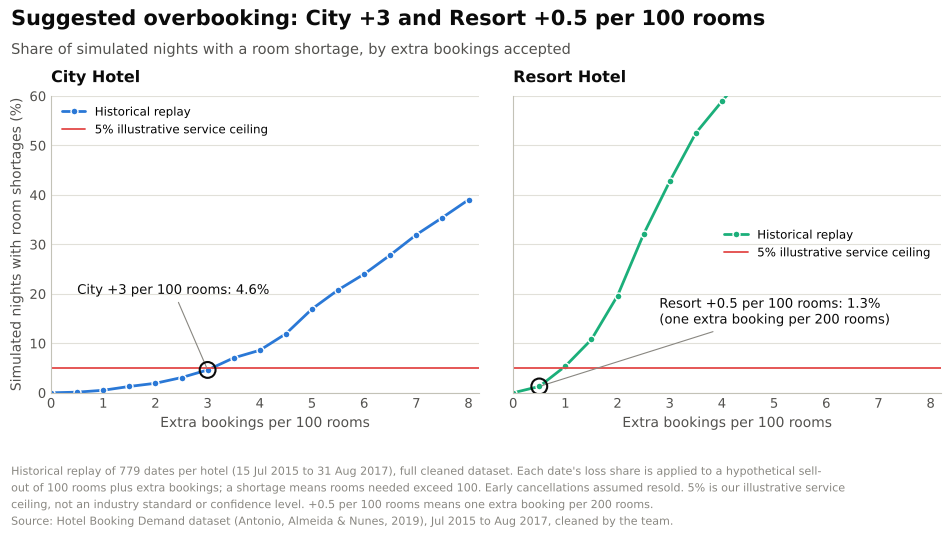

In [27]:
o_grid = np.arange(0, 8.5, 0.5)
CEILING = 0.05        # our illustrative service ceiling: shortages on no more than 5% of simulated nights
risk = {h: np.array([walk_risk(nights.loc[nights.hotel == h, 'share'], o) for o in o_grid]) for h in HOTELS}
rec = {h: max(o for o, r in zip(o_grid, risk[h]) if r <= CEILING) for h in HOTELS}
by_year = {}
for h in HOTELS:
    g = nights[nights.hotel == h]
    by_year[h] = {int(yr): max(o for o in o_grid if walk_risk(gy.share, o) <= CEILING) for yr, gy in g.groupby(g.night.dt.year)}
R['overbooking_rule_5pct'] = {h: {'recommended_per_100': rec[h], 'risk_at_recommended': round(risk[h][list(o_grid).index(rec[h])], 4),
                                  'risk_curve': dict(zip(o_grid.tolist(), risk[h].round(4).tolist())), 'by_year': by_year[h]} for h in HOTELS}
print({h: (rec[h], by_year[h]) for h in HOTELS})

fig, axes = chart(f'Suggested overbooking: City +{rec["City Hotel"]:g} and Resort +{rec["Resort Hotel"]:g} per 100 rooms',
                  'Share of simulated nights with a room shortage, by extra bookings accepted', ncols=2, sharey=True)
for ax, h in zip(axes, HOTELS):
    i = list(o_grid).index(rec[h])
    ax.plot(o_grid, risk[h], color=HOTEL_COLOR[h], marker='o', markersize=5, markeredgecolor='white', label='Historical replay')
    ax.axhline(CEILING, color=LOSS, linewidth=1.3, label='5% illustrative service ceiling')
    ax.scatter([rec[h]], [risk[h][i]], s=130, facecolor='none', edgecolor=INK, linewidth=1.5, zorder=4)
    label = f'{h.split()[0]} +{rec[h]:g} per 100 rooms: {risk[h][i]:.1%}'
    if rec[h] < 1:
        label += f'\n(one extra booking per {100 / rec[h]:g} rooms)'
    ax.annotate(label, (rec[h], risk[h][i]), xytext=(0.5, 0.2) if h == 'City Hotel' else (2.8, 0.14), textcoords='data',
                fontsize=9.5, color=INK, ha='left', arrowprops=dict(arrowstyle='-', color=MUTED, linewidth=0.8))
    ax.set_title(h)
    ax.set_xlim(0, 8.2)
    ax.set_ylim(0, 0.6)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0, symbol=''))
    ax.set_xlabel('Extra bookings per 100 rooms')
    ax.legend(loc='upper left' if h == 'City Hotel' else 'center right', fontsize=8.5)
axes[0].set_ylabel('Simulated nights with room shortages (%)')
save(fig, '16_walk_risk', f'Historical replay of {ob["City Hotel"]["nights"]} dates per hotel (15 Jul 2015 to 31 Aug 2017), full cleaned dataset. Each date\'s loss share is applied to a hypothetical '
     'sell-out of 100 rooms plus extra bookings; a shortage means rooms needed exceed 100. Early cancellations assumed resold. 5% is our illustrative service ceiling, not an industry '
     'standard or confidence level. +0.5 per 100 rooms means one extra booking per 200 rooms.', wrap=150, wspace=0.08, bottom=0.27)

{
 "City Hotel": {
  "walk_cost_1.5x_adr": {
   "best_per_100": 8.0,
   "net_eur_per_night_per_100": 485.0,
   "risk_at_best": 0.3902
  },
  "walk_cost_2x_adr": {
   "best_per_100": 7.0,
   "net_eur_per_night_per_100": 443.0,
   "risk_at_best": 0.3196
  },
  "walk_cost_3x_adr": {
   "best_per_100": 6.0,
   "net_eur_per_night_per_100": 388.0,
   "risk_at_best": 0.2401
  },
  "walk_cost_5x_adr": {
   "best_per_100": 5.0,
   "net_eur_per_night_per_100": 326.0,
   "risk_at_best": 0.1694
  }
 },
 "Resort Hotel": {
  "walk_cost_1.5x_adr": {
   "best_per_100": 3.0,
   "net_eur_per_night_per_100": 159.0,
   "risk_at_best": 0.4275
  },
  "walk_cost_2x_adr": {
   "best_per_100": 2.5,
   "net_eur_per_night_per_100": 144.0,
   "risk_at_best": 0.3209
  },
  "walk_cost_3x_adr": {
   "best_per_100": 2.0,
   "net_eur_per_night_per_100": 122.0,
   "risk_at_best": 0.1964
  },
  "walk_cost_5x_adr": {
   "best_per_100": 2.0,
   "net_eur_per_night_per_100": 95.0,
   "risk_at_best": 0.1964
  }
 }
}


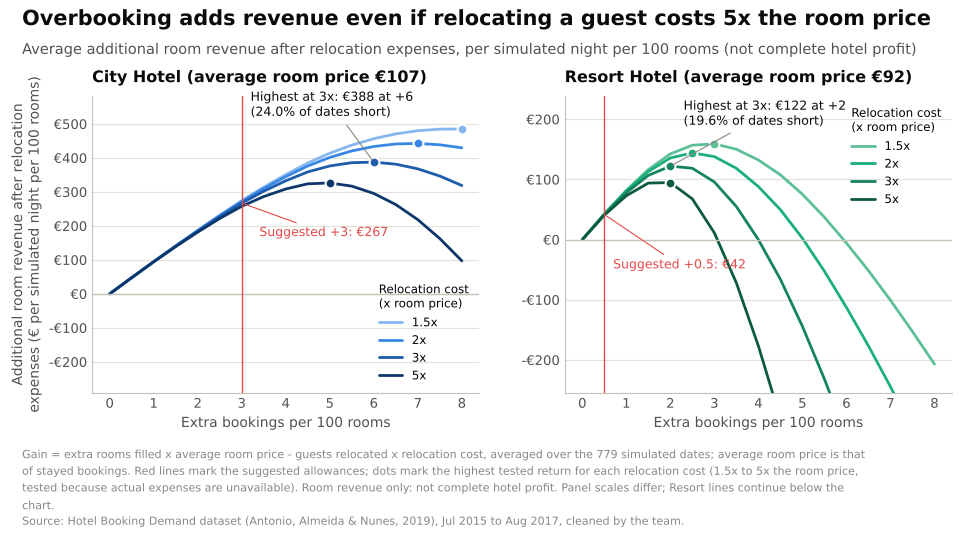

In [28]:
# Cost view: extra rooms filled vs guests walked, valued at the average room rate
adr_stay = df[df.is_canceled == 0].groupby('hotel').adr.mean()
MULTS = [1.5, 2, 3, 5]
cost = {}
for h in HOTELS:
    s = nights.loc[nights.hotel == h, 'share'].values
    base_filled = (np.minimum(1 - s, 1) * 100).mean()
    curves = {}
    for mlt in MULTS:
        vals = []
        for o in o_grid:
            x = (1 + o / 100) * (1 - s)
            filled, walked = (np.minimum(x, 1) * 100).mean(), (np.maximum(x - 1, 0) * 100).mean()
            vals.append(((filled - base_filled) - mlt * walked) * adr_stay[h])
        curves[mlt] = np.array(vals)
    cost[h] = curves
fill_table = {h: {float(o): {'empty_rooms_per_100': round(float(np.maximum(1 - (1 + o / 100) * (1 - nights.loc[nights.hotel == h, 'share'].values), 0).mean() * 100), 2),
                             'walked_per_100': round(float(np.maximum((1 + o / 100) * (1 - nights.loc[nights.hotel == h, 'share'].values) - 1, 0).mean() * 100), 3)}
                  for o in [0, 0.5, 1, 2, 3, 4, 5, 6]} for h in HOTELS}
R['overbooking_cost'] = {h: {f'walk_cost_{m}x_adr': {'best_per_100': float(o_grid[np.argmax(c)]), 'net_eur_per_night_per_100': round(float(c.max()), 0),
                                                     'risk_at_best': round(float(risk[h][np.argmax(c)]), 4)} for m, c in cost[h].items()}
                         for h in HOTELS}
R['overbooking_fill'] = fill_table
R['adr_stayed'] = adr_stay.round(2).to_dict()
print(json.dumps(R['overbooking_cost'], indent=1))

fig, axes = chart('Overbooking adds revenue even if relocating a guest costs 5x the room price',
                  'Average additional room revenue after relocation expenses, per simulated night per 100 rooms (not complete hotel profit)', ncols=2)
for ax, h in zip(axes, HOTELS):
    for (mlt, c), col in zip(cost[h].items(), RAMP[h]):
        ax.plot(o_grid, c, color=col, label=f'{mlt:g}x')
        i = int(np.argmax(c))
        ax.scatter([o_grid[i]], [c[i]], s=50, color=col, edgecolor='white', linewidth=1.5, zorder=3)
    ax.axhline(0, color=AXIS, linewidth=1)
    ax.axvline(rec[h], color=LOSS, linewidth=1)
    top_val = max(c.max() for c in cost[h].values())
    ax.set_ylim(-0.6 * top_val if h == 'City Hotel' else -1.6 * top_val, top_val * (1.2 if h == 'City Hotel' else 1.5))
    # value labels on the 3x scenario: at the suggested allowance and at the highest tested return
    c3 = cost[h][3]
    i_sug, i_best = list(o_grid).index(rec[h]), int(np.argmax(c3))
    sug_xy = (rec[h] + 0.4, c3[i_sug] - 0.2 * top_val) if h == 'City Hotel' else (rec[h] + 0.2, -0.3 * top_val)
    best_xy = (3.2, 1.08 * top_val) if h == 'City Hotel' else (2.3, 1.2 * top_val)
    ax.annotate(f'Suggested +{rec[h]:g}: €{c3[i_sug]:,.0f}', (rec[h], c3[i_sug]), xytext=sug_xy, fontsize=9, color=LOSS, ha='left',
                arrowprops=dict(arrowstyle='-', color=LOSS, linewidth=0.8))
    ax.annotate(f'Highest at 3x: €{c3[i_best]:,.0f} at +{o_grid[i_best]:g}\n({risk[h][i_best]:.1%} of dates short)', (o_grid[i_best], c3[i_best]),
                xytext=best_xy, fontsize=9, color=INK, ha='left', arrowprops=dict(arrowstyle='-', color=MUTED, linewidth=0.8))
    ax.set_title(f'{h} (average room price €{adr_stay[h]:.0f})')
    ax.yaxis.set_major_formatter(FuncFormatter(eur))
    ax.set_xlabel('Extra bookings per 100 rooms')
    ax.legend(title='Relocation cost\n(x room price)', title_fontsize=8.5, loc='lower right' if h == 'City Hotel' else 'upper right',
              fontsize=8.5, alignment='left')
axes[0].set_ylabel('Additional room revenue after relocation\nexpenses (€ per simulated night per 100 rooms)')
save(fig, '17_overbooking_cost', 'Gain = extra rooms filled x average room price - guests relocated x relocation cost, averaged over the 779 simulated dates; average room price is that of stayed bookings. '
     'Red lines mark the suggested allowances; dots mark the highest tested return for each relocation cost (1.5x to 5x the room price, tested because actual expenses are unavailable). '
     'Room revenue only: not complete hotel profit. Panel scales differ; Resort lines continue below the chart.',
     wrap=150, wspace=0.22, bottom=0.27, left=0.11)

In [29]:
# Check the headline numbers against the final report. Everything is computed from the data above; the report values below are
# only what we compare against, never inputs. If a line says DIFFERS, investigate rather than adjust the numbers.
def shortage_dates(share, k):
    """Dates on which (100 + k) x (1 - loss share) > 100."""
    return int(((100 + k) * (1 - share.values) > 100).sum())

rows = []
for h, k, rep_n, rep_pct in [('City Hotel', rec['City Hotel'], 36, 4.6), ('Resort Hotel', rec['Resort Hotel'], 10, 1.3)]:
    share = nights.loc[nights.hotel == h, 'share']
    n_short = shortage_dates(share, k)
    assert n_short == round(walk_risk(share, k) * len(share)), 'two shortage calculations disagree'
    rows.append([h, f'+{k:g}', 'shortage dates', f'{n_short}/{len(share)}', f'{rep_n}/779', n_short == rep_n])
    rows.append([h, f'+{k:g}', 'shortage frequency (%)', round(n_short / len(share) * 100, 1), rep_pct, round(n_short / len(share) * 100, 1) == rep_pct])
for h, k, rep_gain, rep_pct in [('City Hotel', 3, 267.12, None), ('City Hotel', 6, 387.50, 24.0),
                                ('Resort Hotel', 0.5, 41.77, None), ('Resort Hotel', 2, 122.05, 19.6)]:
    i = list(o_grid).index(k)
    gain = round(float(cost[h][3][i]), 2)
    rows.append([h, f'+{k:g}', 'gain at 3x room price (€)', gain, rep_gain, gain == rep_gain])
    if rep_pct is not None:
        rows.append([h, f'+{k:g}', 'shortage frequency (%)', round(risk[h][i] * 100, 1), rep_pct, round(risk[h][i] * 100, 1) == rep_pct])
for h, rep in [('City Hotel', 106.62), ('Resort Hotel', 92.01)]:
    rows.append([h, '', 'average room price, stayed (€)', round(float(adr_stay[h]), 2), rep, round(float(adr_stay[h]), 2) == rep])
checks = pd.DataFrame(rows, columns=['hotel', 'extra per 100', 'measure', 'computed', 'report', 'matches'])
R['overbooking_checks_vs_report'] = checks.astype(str).to_dict(orient='records')
print('ALL MATCH THE REPORT' if checks.matches.all() else 'SOME VALUES DIFFER FROM THE REPORT - investigate')
checks

ALL MATCH THE REPORT


,hotel,extra per 100,measure,computed,report,matches
0,City Hotel,+3,shortage dates,36/779,36/779,True
1,City Hotel,+3,shortage frequency (%),4.6,4.6,True
2,Resort Hotel,+0.5,shortage dates,10/779,10/779,True
3,Resort Hotel,+0.5,shortage frequency (%),1.3,1.3,True
4,City Hotel,+3,gain at 3x room price (€),267.12,267.12,True
5,City Hotel,+6,gain at 3x room price (€),387.5,387.5,True
6,City Hotel,+6,shortage frequency (%),24.0,24.0,True
7,Resort Hotel,+0.5,gain at 3x room price (€),41.77,41.77,True
8,Resort Hotel,+2,gain at 3x room price (€),122.05,122.05,True
9,Resort Hotel,+2,shortage frequency (%),19.6,19.6,True


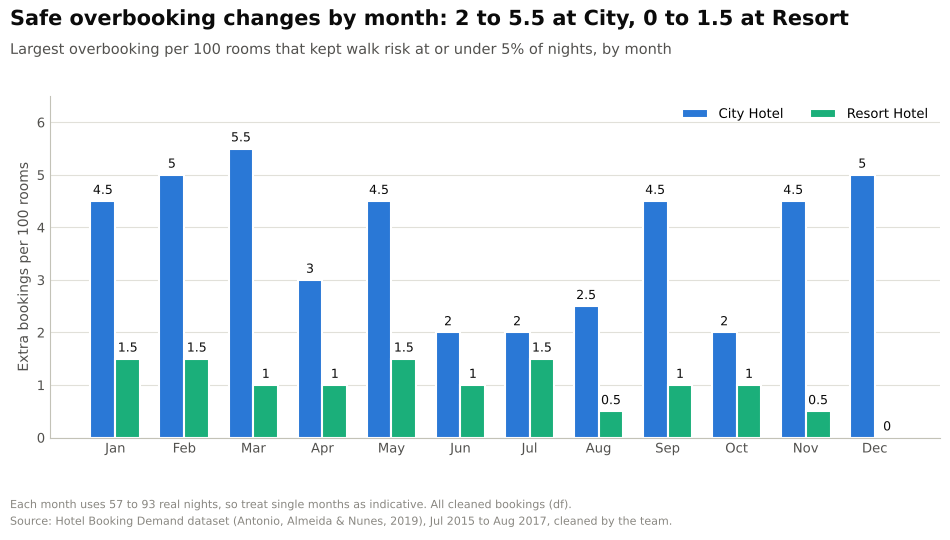

In [30]:
nm = nights.assign(month=nights.night.dt.month)
month_rec = {h: {} for h in HOTELS}
for (h, mth), g in nm.groupby(['hotel', 'month']):
    month_rec[h][mth] = max(o for o in o_grid if walk_risk(g.share, o) <= 0.05)
month_rec = pd.DataFrame(month_rec)
month_n = nm.groupby(['hotel', 'month']).size().unstack(0)
R['overbooking_by_month'] = {h: {int(k): float(v) for k, v in month_rec[h].items()} for h in HOTELS}
fig, ax = chart(f'Safe overbooking changes by month: {month_rec["City Hotel"].min():g} to {month_rec["City Hotel"].max():g} at City, '
                f'{month_rec["Resort Hotel"].min():g} to {month_rec["Resort Hotel"].max():g} at Resort',
                'Largest overbooking per 100 rooms that kept walk risk at or under 5% of nights, by month')
xm = np.arange(12)
for i, h in enumerate(HOTELS):
    ax.bar(xm + (i - 0.5) * 0.36, month_rec[h].values, width=0.36, color=HOTEL_COLOR[h], edgecolor='white', linewidth=1.5, label=h)
    for xi, v in zip(xm + (i - 0.5) * 0.36, month_rec[h].values):
        ax.text(xi, v + 0.08, f'{v:g}', ha='center', va='bottom', fontsize=9, color=INK)
ax.set_xticks(xm, [m[:3] for m in MONTHS])
ax.set_ylabel('Extra bookings per 100 rooms')
ax.set_ylim(0, 6.5)
ax.legend(loc='upper right', ncol=2)
save(fig, '18_overbooking_by_month', f'Each month uses {month_n.values.min()} to {month_n.values.max()} real nights, so treat single months as indicative. All cleaned bookings (df).')

In [31]:
rng = np.random.default_rng(2702)   # seed for the random 25% of targeted late cancellations avoided below
# If the deposit cuts late cancellations in the target group by 25%, how much should overbooking come down?
sim = df.copy()
tgt = (sim.in_deposit_analysis == 1) & deposit_rule(sim)
flip = tgt & (sim.late_cancel == 1) & (rng.random(len(sim)) < 0.25)
sim.loc[flip, 'late_cancel'] = 0
sim.loc[flip, 'is_canceled'] = 0
n2 = nightly(sim)
rec_after = {h: max(o for o in o_grid if walk_risk(n2.loc[n2.hotel == h, 'share'], o) <= 0.05) for h in HOTELS}
R['overbooking_after_deposit_25pct'] = rec_after
print('Recommended overbooking per 100 rooms, before vs after a deposit that cuts targeted late cancels by 25%:', rec, rec_after)

Recommended overbooking per 100 rooms, before vs after a deposit that cuts targeted late cancels by 25%: {'City Hotel': np.float64(3.0), 'Resort Hotel': np.float64(0.5)} {'City Hotel': np.float64(2.0), 'Resort Hotel': np.float64(0.5)}


## 11. Summary of the answer

In [32]:
summary = pd.DataFrame({
    h: {'Late-cancel loss per year (deposit subset)': f"€{dep[dep.hotel == h].late_value.sum() / YEARS:,.0f}",
        'Who pays a deposit': 'Booked <=30 days ahead' + (' or worth €540+' if h == 'City Hotel' else '') + ', or cancelled before; loyal guests exempt',
        'Share of bookings asked': f"{rule_stats[h]['share_asked']:.0%}",
        'Share of late-cancel loss covered': f"{rule_stats[h]['share_late_eur_covered']:.0%}",
        'Deposit': f"First night (avg €{dep_sizing[h]['avg_first_night_eur']:.0f}), kept if cancelled <=7 days before or no-show",
        'Recovered per year (0% to 50% response)': f"€{dep_sizing[h]['scenarios'][Q_LABELS[0]]['recovered_eur_per_year']:,.0f} to €{dep_sizing[h]['scenarios'][Q_LABELS[-1]]['recovered_eur_per_year']:,.0f}",
        'Pays off unless it loses more than': f"{dep_sizing[h]['scenarios'][Q_LABELS[0]]['break_even_lost_bookings']:.1%} of targeted revenue (no response)",
        'Overbook per 100 rooms (5% shortage ceiling)': f"+{rec[h]:g} (yearly range +{min(by_year[h].values()):g} to +{max(by_year[h].values()):g})",
        'Overbook if relocation cost = 3x room price': f"+{R['overbooking_cost'][h]['walk_cost_3x_adr']['best_per_100']:g}",
        'After deposit cuts late cancels 25%': f"+{rec_after[h]:g}"} for h in HOTELS})
R['summary'] = summary.to_dict()
with open('results.json', 'w') as f:
    json.dump(R, f, indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
summary

,City Hotel,Resort Hotel
Late-cancel loss per year (deposit subset),"€682,793","€198,623"
Who pays a deposit,"Booked <=30 days ahead or worth €540+, or canc...","Booked <=30 days ahead, or cancelled before; l..."
Share of bookings asked,45%,37%
Share of late-cancel loss covered,73%,51%
Deposit,"First night (avg €119), kept if cancelled <=7 ...","First night (avg €91), kept if cancelled <=7 d..."
Recovered per year (0% to 50% response),"€143,437 to €319,515","€38,570 to €70,049"
Pays off unless it loses more than,4.1% of targeted revenue (no response),3.0% of targeted revenue (no response)
Overbook per 100 rooms (5% shortage ceiling),+3 (yearly range +2 to +4.5),+0.5 (yearly range +0 to +1)
Overbook if relocation cost = 3x room price,+6,+2
After deposit cuts late cancels 25%,+2,+0.5


## 12. Download every chart as a PNG
In Colab this zips the `charts` folder and downloads `charts.zip`. You can also open the Files panel, open `charts`, and right-click any PNG > Download.

In [33]:
shutil.make_archive('charts', 'zip', CHART_DIR)
print(sorted(os.listdir(CHART_DIR)))
try:
    from google.colab import files
    files.download('charts.zip')
except ImportError:
    print('Not running in Colab: charts.zip is saved next to this notebook.')

['01_outcome_by_hotel.png', '02_city_resort_gap.png', '03_monthly_empty_rooms.png', '04_money_by_hotel.png', '05_money_by_channel.png', '06_lead_time_early_late.png', '07_late_loss_by_lead.png', '08_segment_lead_heatmap.png', '09_channel_dumbbell.png', '10_history.png', '11_requests_by_lead.png', '12_parking_leakage.png', '13a_why_540.png', '13b_deposit_targeting.png', '14_deposit_scenarios.png', '16_walk_risk.png', '17_overbooking_cost.png', '18_overbooking_by_month.png']
Not running in Colab: charts.zip is saved next to this notebook.
